# Diccionario inverso basado en normas de asociación de palabras y teoría de grafos

**Procesamiento de Lenguaje Natural · Proyecto de la Unidad 2**
Universidad Autónoma de Yucatán · Facultad de Matemáticas · Dr. Jorge Carlos Reyes Magaña

| | |
|---|---|
| **Modalidad** | C · Extensión metodológica sobre las normas de asociación del español de México (NAP) |
| **Extensiones** | (1) PageRank personalizado sobre grafo no dirigido y dirigido · (2) Fusión de rankings (RRF) entre grafos y node2vec |
| **Integrantes** | *[Nombre(s) del equipo]* |
| **Fecha** | 10 de noviembre de 2026 |

---

## Contenido

0. [Configuración y reproducibilidad](#0.-Configuración-y-reproducibilidad)
1. [Normas de asociación y construcción del grafo](#1.-Normas-de-asociación-y-construcción-del-grafo)
2. [Caracterización del grafo](#2.-Caracterización-del-grafo)
3. [Preprocesamiento de las definiciones](#3.-Preprocesamiento-de-las-definiciones)
4. [Conjunto de evaluación y cobertura](#4.-Conjunto-de-evaluación-y-cobertura)
5. [Modelos de centralidad](#5.-Modelos-de-centralidad)
6. [Modelo híbrido con node2vec](#6.-Modelo-híbrido-con-node2vec)
7. [Extensiones: PageRank personalizado y fusión RRF](#7.-Extensiones:-PageRank-personalizado-y-fusión-RRF)
8. [Evaluación comparativa](#8.-Evaluación-comparativa)
9. [Análisis de errores](#9.-Análisis-de-errores)
10. [Discusión y conclusiones](#10.-Discusión-y-conclusiones)
11. [Demostración interactiva](#11.-Demostración-interactiva)
12. [Referencias](#12.-Referencias)

> **Cómo reproducir.** Ejecutar *Run all*. Todas las cifras de las tablas salen de este cuaderno con `SEMILLA = 42`.
> Los resultados se guardan en `resultados/` (`resultados.json`, tablas CSV y figuras PNG), que es lo que alimenta el reporte técnico.

## 0. Configuración y reproducibilidad

Un diccionario inverso parte de una descripción en lenguaje natural y devuelve palabras candidatas ordenadas. Aquí el
conocimiento léxico viene de las normas de asociación de palabras (NAP) representadas como grafo, siguiendo el modelo de búsqueda léxica
de Reyes-Magaña et al. (2019). Este cuaderno reimplementa los modelos vistos en clase, los compara con un modelo híbrido (node2vec)
y agrega dos extensiones metodológicas.

In [1]:
import sys, os, re, json, time, math, random, pickle, hashlib, warnings, subprocess, collections
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    # En Colab se instalan las dependencias que no vienen de fábrica (en local: pip install -r requirements.txt).
    # Si Colab pide reiniciar la sesión tras instalar, reiniciar y volver a ejecutar todo.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlrd", "node2vec", "gradio",
                    "https://github.com/explosion/spacy-models/releases/download/es_core_news_sm-3.8.0/es_core_news_sm-3.8.0-py3-none-any.whl"],
                   check=False)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ---- Reproducibilidad -------------------------------------------------------------------------------------------
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# ---- Rutas ------------------------------------------------------------------------------------------------------
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/gdrive")
    RAIZ = Path("/content/gdrive/MyDrive/PLN 26/Diccionario inverso")   # carpeta con datos/ y resultados/
else:
    RAIZ = Path.cwd()
DATOS, RESULTADOS = RAIZ / "datos", RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

# ---- Parámetros globales ----------------------------------------------------------------------------------------
USAR_SINTETICO = False     # True fuerza el conjunto de PRUEBA (descripciones generadas, no válidas como resultado final)
TIEMPO_MIN = 0.1           # s; acota tiempos de respuesta de 0 s (imposibles) para no crear aristas de costo cero
TOP_K_CANDIDATOS = 100     # longitud de la lista de candidatos que se guarda por definición (como en clase)

# ---- Estilo de gráficas y tablas --------------------------------------------------------------------------------
COLOR = dict(primario="#1F3A5F", acento="#C8553D", verde="#2E7D5B", dorado="#C9A227", gris="#6B7280", claro="#E5E7EB")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E5E7EB", "grid.linewidth": 0.8, "axes.edgecolor": "#9CA3AF",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10, "font.family": "DejaVu Sans",
    "axes.prop_cycle": plt.cycler(color=[COLOR["primario"], COLOR["acento"], COLOR["verde"], COLOR["dorado"], COLOR["gris"]]),
})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

RES = {}   # acumulador de resultados que se vuelca a resultados/resultados.json

def guardar_figura(fig, nombre):
    fig.savefig(RESULTADOS / f"{nombre}.png")
    plt.show()

def guardar_resultados():
    with open(RESULTADOS / "resultados.json", "w", encoding="utf-8") as f:
        json.dump(RES, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print(f"Python {sys.version.split()[0]} · networkx {nx.__version__} · numpy {np.__version__} · pandas {pd.__version__}")
print(f"Carpeta de trabajo: {RAIZ}")

Python 3.12.6 · networkx 3.7 · numpy 1.26.4 · pandas 3.0.6
Carpeta de trabajo: C:\dev\otros\PLN PRO 2


## 1. Normas de asociación y construcción del grafo

### 1.1 Lectura de NAP

El archivo `NAP.xls` agrupa, por cada palabra estímulo, la lista de respuestas con su frecuencia, el tiempo medio de respuesta
(segundos) y el porcentaje de asociación (fuerza). La lectura sigue la lógica del cuaderno de clase (`Construye_Grafo`), pero en
**un solo recorrido hacia un `DataFrame`** y con una limpieza explícita que reporta cuántos registros se descartan.

Diferencias respecto a la versión de clase, todas contabilizadas más abajo:

* Las respuestas inválidas marcadas con `*` en NAP (lema `=`) se descartan. En el grafo de clase ese símbolo aparecía como un nodo
  (`('abeja','=')`, `('=','bicicleta')`) que conectaba palabras sin relación.
* El último estímulo (`zapato`) no trae el lema en la columna de lemas; la versión de clase lo registraba con el nombre vacío `''`.
* Respuestas que son números o marcas de tiempo (`8.0`, `[??:??/2/...]`) se descartan.
* Si dos respuestas distintas comparten lema (*calentar* y *calentarse*), se **fusionan** sumando frecuencias y fuerza, y promediando
  el tiempo ponderado por frecuencia, en vez de que la última sobrescriba a la primera.

In [2]:
def leer_nap_xls(ruta):
    """Lee NAP.xls y devuelve (pares crudos, contador de descartes)."""
    import xlrd
    hoja = xlrd.open_workbook(str(ruta)).sheet_by_index(0)
    filas, estimulo, descartes = [], None, collections.Counter()
    for f in range(hoja.nrows):
        c0 = hoja.cell(f, 0).value
        if c0 == "======":                                   # inicio de bloque: la fila siguiente es el estímulo
            lema = str(hoja.cell(f + 1, 4).value).strip()
            estimulo = (lema or str(hoja.cell(f + 1, 0).value).strip()).lower()
            if not lema:
                descartes["estímulo sin lema (se usa la forma original)"] += 1
            continue
        if c0 in ("--PALABRAS--", "") or hoja.cell(f, 1).value == "":
            continue                                          # encabezados y fila del propio estímulo
        lema = str(hoja.cell(f, 4).value).strip().lower()
        if lema == "=" or c0 == "*":
            descartes["respuesta inválida (*, lema '=')"] += 1; continue
        if lema.startswith("[") or not re.search(r"[a-záéíóúüñ]", lema):
            descartes["número o marca de tiempo"] += 1; continue
        if lema == estimulo:
            descartes["autoasociación (estímulo = respuesta)"] += 1; continue
        filas.append((estimulo, lema, float(hoja.cell(f, 1).value), float(hoja.cell(f, 2).value), float(hoja.cell(f, 3).value)))
    crudo = pd.DataFrame(filas, columns=["estimulo", "respuesta", "frecuencia", "tiempo", "fuerza"])
    return crudo, descartes

def consolidar_normas(crudo):
    """Fusiona pares con el mismo (estímulo, lema): suma frecuencia y fuerza; tiempo medio ponderado por frecuencia."""
    c = crudo.assign(ft=crudo.frecuencia * crudo.tiempo)
    g = c.groupby(["estimulo", "respuesta"], as_index=False).agg(frecuencia=("frecuencia", "sum"), ft=("ft", "sum"), fuerza=("fuerza", "sum"))
    g["tiempo_medio"] = (g.ft / g.frecuencia).round(4)
    g["fuerza"] = g.fuerza.round(6)
    g["frecuencia"] = g.frecuencia.astype(int)
    return g[["estimulo", "respuesta", "frecuencia", "tiempo_medio", "fuerza"]].sort_values(["estimulo", "frecuencia"], ascending=[True, False]).reset_index(drop=True)

RUTA_CSV, RUTA_XLS = DATOS / "nap_normas.csv", DATOS / "NAP.xls"
if RUTA_XLS.exists():
    crudo, descartes = leer_nap_xls(RUTA_XLS)
    normas = consolidar_normas(crudo)
    normas.to_csv(RUTA_CSV, index=False, encoding="utf-8-sig")
    RES["normas"] = dict(pares_crudos=len(crudo) + sum(v for k, v in descartes.items() if not k.startswith("estímulo")),
                         pares_validos=len(crudo), pares_consolidados=len(normas), descartes=dict(descartes))
    print(f"NAP.xls leído: {len(crudo):,} pares válidos → {len(normas):,} tras fusionar variantes del mismo lema.")
    display(pd.Series(descartes, name="registros").to_frame())
else:
    normas = pd.read_csv(RUTA_CSV, encoding="utf-8-sig")
    print(f"Se usó {RUTA_CSV.name} (no se encontró NAP.xls): {len(normas):,} pares.")

display(normas.head(8))

NAP.xls leído: 13,299 pares válidos → 13,171 tras fusionar variantes del mismo lema.


,registros
"respuesta inválida (*, lema '=')",4
número o marca de tiempo,30
autoasociación (estímulo = respuesta),3
estímulo sin lema (se usa la forma original),1


,estimulo,respuesta,frecuencia,tiempo_medio,fuerza
0,abeja,miel,137,3.2750,49.818180
1,abeja,picar,23,3.7052,8.363636
2,abeja,picadura,18,4.2061,6.545455
3,abeja,reina,8,2.9987,2.909091
4,abeja,amarillo,7,4.7757,2.545455
5,abeja,flor,6,2.7433,2.181818
6,abeja,panal,6,5.1767,2.181818
7,abeja,polen,6,4.9367,2.181818


### 1.2 Ponderaciones y paso de similitud a distancia

Las tres medidas de NAP son **similitudes**: a mayor frecuencia, fuerza de asociación o rapidez, más cercanas están dos palabras.
Los algoritmos de caminos más cortos (intermediación, cercanía) interpretan el peso de una arista como un **costo**, así que
para ellos hay que invertir la escala. Cada arista guarda ambas versiones:

| Ponderación | Similitud (para PageRank, vector propio y node2vec) | Distancia (para caminos más cortos) | Justificación |
|---|---|---|---|
| **Frecuencia** | `f` | `1 / f` | Función decreciente y siempre positiva; una respuesta dada por muchos participantes queda a “distancia corta”. |
| **Tiempo** | `1 / t` | `t` | El tiempo de respuesta ya es un costo: responder rápido indica asociación más accesible. Se acota `t ≥ 0.1 s`. |
| **Asociación** | `FA` (%) | `100 − FA` | Transformación lineal con `FA ∈ (0, 100)`; conserva el orden y evita distancias nulas (`FA` máxima observada ≈ 74). |

En el grafo **no dirigido** la arista `{a, b}` reúne ambas direcciones (`a→b` y `b→a`): frecuencia total (suma), fuerza máxima y tiempo medio
ponderado. En el grafo **dirigido** (extensión 1) cada arista `estímulo→respuesta` conserva sus propios valores.

In [3]:
PONDERACIONES = ["asociacion", "frecuencia", "tiempo"]

def _atributos(frecuencia, tiempo, fuerza):
    t = max(tiempo, TIEMPO_MIN)
    return dict(frecuencia=frecuencia, tiempo=tiempo, fuerza=fuerza,
                d_frecuencia=1.0 / frecuencia, d_tiempo=t, d_asociacion=100.0 - fuerza,
                s_frecuencia=float(frecuencia), s_tiempo=1.0 / t, s_asociacion=fuerza)

def construir_grafos(normas):
    """Devuelve (grafo no dirigido, grafo dirigido estímulo→respuesta) con atributos de las tres ponderaciones."""
    n = normas.assign(a=np.where(normas.estimulo < normas.respuesta, normas.estimulo, normas.respuesta),
                      b=np.where(normas.estimulo < normas.respuesta, normas.respuesta, normas.estimulo),
                      ft=normas.frecuencia * normas.tiempo_medio)
    g = n.groupby(["a", "b"], as_index=False).agg(frecuencia=("frecuencia", "sum"), ft=("ft", "sum"), fuerza=("fuerza", "max"))
    G = nx.Graph()
    for a, b, f, ft, fu in g.itertuples(index=False):
        G.add_edge(a, b, **_atributos(int(f), ft / f, fu))
    D = nx.DiGraph()
    for e, r, f, t, fu in normas.itertuples(index=False):
        D.add_edge(e, r, **_atributos(int(f), t, fu))
    return G, D

G, D = construir_grafos(normas)
ESTIMULOS = set(normas.estimulo)
print(f"Grafo no dirigido: {G.number_of_nodes():,} nodos, {G.number_of_edges():,} aristas")
print(f"Grafo dirigido   : {D.number_of_nodes():,} nodos, {D.number_of_edges():,} aristas")
print(f"Nodos que fueron palabra estímulo: {len(ESTIMULOS)}")

Grafo no dirigido: 4,222 nodos, 12,834 aristas
Grafo dirigido   : 4,222 nodos, 13,171 aristas
Nodos que fueron palabra estímulo: 232


## 2. Caracterización del grafo

Estadísticas descriptivas del grafo no dirigido: tamaño, grado medio, conectividad, agrupamiento y distribución de grado.

In [4]:
def caracterizar(G):
    grados = np.array([d for _, d in G.degree()])
    comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    return {
        "nodos": G.number_of_nodes(), "aristas": G.number_of_edges(),
        "grado_medio": float(grados.mean()), "grado_mediano": float(np.median(grados)), "grado_maximo": int(grados.max()),
        "densidad": nx.density(G), "componentes_conexas": len(comps), "tamano_componente_mayor": comps[0],
        "tamanos_componentes": comps[:10],
        "coef_agrupamiento_medio": nx.average_clustering(G), "transitividad": nx.transitivity(G),
    }

est = caracterizar(G)
RES["grafo"] = est
tabla_est = pd.DataFrame({
    "Medida": ["Nodos", "Aristas", "Grado medio", "Grado mediano", "Grado máximo", "Densidad", "Componentes conexas",
               "Tamaño de la componente mayor", "Coeficiente de agrupamiento medio", "Transitividad"],
    "Valor": [f"{est['nodos']:,}", f"{est['aristas']:,}", f"{est['grado_medio']:.2f}", f"{est['grado_mediano']:.0f}", f"{est['grado_maximo']}",
              f"{est['densidad']:.5f}", f"{est['componentes_conexas']}", f"{est['tamano_componente_mayor']:,} ({est['tamano_componente_mayor']/est['nodos']:.1%})",
              f"{est['coef_agrupamiento_medio']:.3f}", f"{est['transitividad']:.3f}"]})
display(tabla_est.style.hide(axis="index"))
print("Tamaños de las componentes (las 10 mayores):", est["tamanos_componentes"])

Medida,Valor
Nodos,"4,222"
Aristas,"12,834"
Grado medio,6.08
Grado mediano,1
Grado máximo,152
Densidad,0.00144
Componentes conexas,1
Tamaño de la componente mayor,"4,222 (100.0%)"
Coeficiente de agrupamiento medio,0.117
Transitividad,0.058


Tamaños de las componentes (las 10 mayores): [4222]


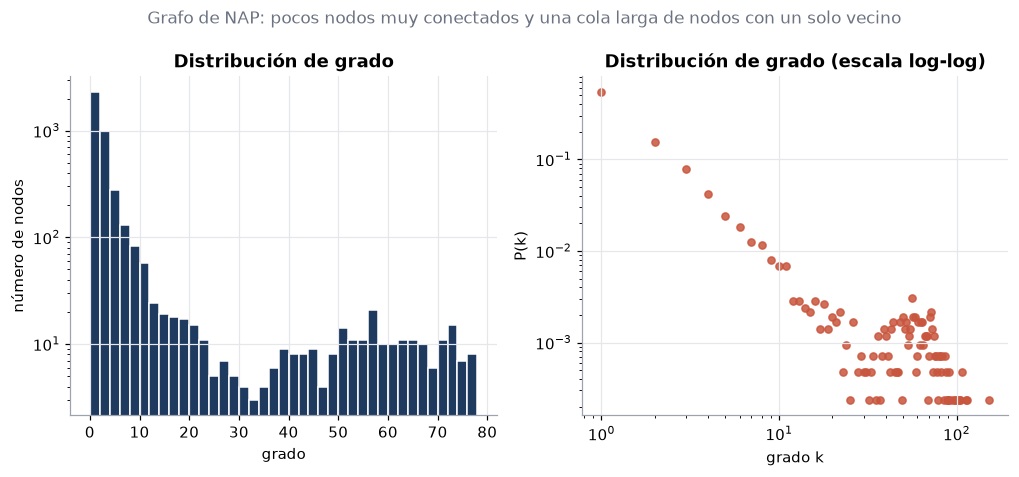

Nodos más conectados (candidatos naturales a dominar los rankings, ver §9):


nodo,grado,es_estimulo
niño,152,sí
agua,114,sí
oso,113,sí
dulce,107,sí
color,107,sí
computador,105,sí
casa,104,sí
grande,102,no
calle,99,sí
camión,98,sí


Nodos con un solo vecino: 2,310 (54.7%)


In [5]:
grados = pd.Series(dict(G.degree()))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(grados, bins=np.arange(0, 80, 2), color=COLOR["primario"], edgecolor="white")
ax[0].set(title="Distribución de grado", xlabel="grado", ylabel="número de nodos", yscale="log")
cuenta = grados.value_counts().sort_index()
ax[1].scatter(cuenta.index, cuenta.values / len(grados), s=22, color=COLOR["acento"], alpha=.85)
ax[1].set(title="Distribución de grado (escala log-log)", xlabel="grado k", ylabel="P(k)", xscale="log", yscale="log")
fig.suptitle("Grafo de NAP: pocos nodos muy conectados y una cola larga de nodos con un solo vecino", y=1.03, fontsize=11, color=COLOR["gris"])
guardar_figura(fig, "fig_distribucion_grado")

hubs = pd.DataFrame({"nodo": grados.nlargest(12).index, "grado": grados.nlargest(12).values})
hubs["es_estimulo"] = hubs.nodo.isin(ESTIMULOS).map({True: "sí", False: "no"})
print("Nodos más conectados (candidatos naturales a dominar los rankings, ver §9):")
display(hubs.style.hide(axis="index"))
print(f"Nodos con un solo vecino: {(grados == 1).sum():,} ({(grados == 1).mean():.1%})")
RES["grafo"]["nodos_grado_1"] = int((grados == 1).sum())
RES["grafo"]["hubs"] = hubs.head(10).to_dict("records")

**Ejemplo ilustrativo.** Vecindad de *abeja*: el grosor de la arista es la fuerza de asociación (`FA`). Los nodos más conectados con *abeja* (*miel*, *picar*, *picadura*…)
son justo las palabras con que una persona la describiría; ese es el principio del diccionario inverso.

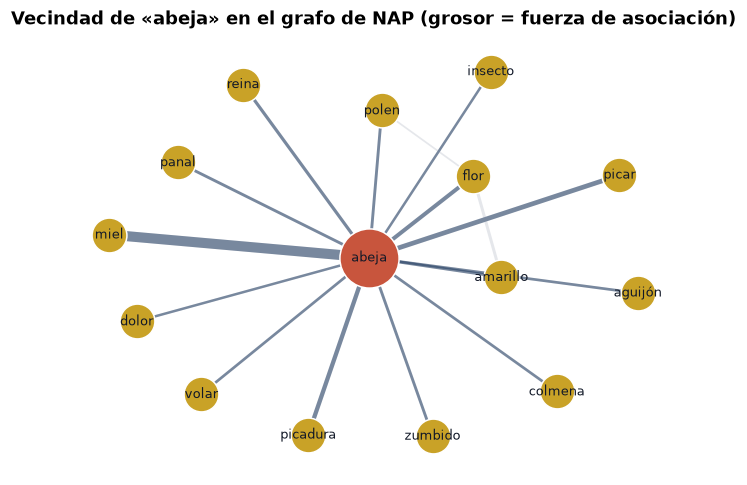

In [6]:
def dibujar_vecindad(G, centro, n_vecinos=14, nombre_fig="fig_vecindad_abeja"):
    vecinos = sorted(G[centro], key=lambda v: -G[centro][v]["fuerza"])[:n_vecinos]
    H = G.subgraph([centro] + vecinos)
    pos = nx.spring_layout(H, seed=SEMILLA, k=0.9, weight=None)
    fig, ax = plt.subplots(figsize=(7.5, 5.2))
    anchos = [0.6 + 6 * math.sqrt(d["fuerza"] / 50) for _, _, d in H.edges(data=True)]
    nx.draw_networkx_edges(H, pos, ax=ax, width=anchos, edge_color=COLOR["claro"], alpha=1)
    nx.draw_networkx_edges(H, pos, edgelist=[(centro, v) for v in vecinos], ax=ax, width=[0.6 + 6 * math.sqrt(G[centro][v]["fuerza"] / 50) for v in vecinos],
                           edge_color=COLOR["primario"], alpha=.55)
    nx.draw_networkx_nodes(H, pos, ax=ax, nodelist=vecinos, node_color=COLOR["dorado"], node_size=520, edgecolors="white")
    nx.draw_networkx_nodes(H, pos, ax=ax, nodelist=[centro], node_color=COLOR["acento"], node_size=1500, edgecolors="white")
    nx.draw_networkx_labels(H, pos, ax=ax, font_size=8.5, font_color="#111827")
    ax.set_axis_off(); ax.set_title(f"Vecindad de «{centro}» en el grafo de NAP (grosor = fuerza de asociación)")
    guardar_figura(fig, nombre_fig)

dibujar_vecindad(G, "abeja")

## 3. Preprocesamiento de las definiciones

Una descripción libre debe convertirse en un subconjunto de nodos del grafo. El proceso sigue el de clase (`limpia_lematiza`):

1. **Limpieza**: minúsculas y eliminación de signos de puntuación.
2. **Palabras funcionales**: se eliminan con la lista de *stopwords* del español de `nltk`.
3. **Lematización** con spaCy (`es_core_news_sm`), palabra por palabra como en clase, para que los resultados sean comparables con la Tabla 1.
4. **Palabras fuera del vocabulario (OOV)**: un lema que no es nodo del grafo se descarta, pero se intenta antes quitar acentos
   (*jardin* → *jardín*) y se contabiliza.
5. **Expresiones multipalabra**: NAP las une con guion bajo (`cepillo_de_dientes`). Si una secuencia de lemas coincide con
   una de ellas, se agrega el nodo correspondiente.

Se agrega un caché de lemas (el mismo vocabulario se repite en todas las descripciones).

In [7]:
import functools, string, unicodedata
import spacy, nltk

nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
try:
    STOP = set(nltk.corpus.stopwords.words("spanish"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    STOP = set(nltk.corpus.stopwords.words("spanish"))
PUNTUACION = str.maketrans("", "", string.punctuation + "¿¡«»“”‘’…–—")
NODOS = set(G.nodes)

def quitar_acentos(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

_sin_acento = collections.defaultdict(set)
for _n in NODOS:
    _sin_acento[quitar_acentos(_n)].add(_n)
SIN_ACENTO = {k: next(iter(v)) for k, v in _sin_acento.items() if len(v) == 1 and k not in NODOS}   # solo si no es ambiguo

@functools.lru_cache(maxsize=None)
def lema_palabra(palabra):
    return nlp(palabra)[0].lemma_.lower()

MODO_LEMATIZACION = "clase"     # "clase": palabra por palabra (como en el cuaderno del profe) · "contexto": oración completa con spaCy

def limpia_lematiza(cadena, modo=None):
    """Pipeline de clase: sin puntuación → sin palabras funcionales → lema. En modo «contexto» el lematizador ve la oración completa."""
    modo = modo or MODO_LEMATIZACION
    if modo == "contexto":
        doc = nlp(cadena)
        lemas = [t.lemma_.lower() for t in doc if not t.is_punct and not t.is_space and t.lower_ not in STOP]
        return [l for l in lemas if l not in STOP]
    tokens = cadena.lower().translate(PUNTUACION).split()
    return [lema_palabra(t) for t in tokens if t not in STOP]

# Expresiones multipalabra de NAP: clave = lemas de contenido de la expresión
MULTIPALABRA = {}
for _n in NODOS:
    if "_" in _n:
        _partes = tuple(lema_palabra(p) for p in _n.split("_") if p not in STOP)
        if len(_partes) >= 2:
            MULTIPALABRA.setdefault(_partes, _n)

@functools.lru_cache(maxsize=None)
def _procesar(texto, modo):
    lemas = limpia_lematiza(texto, modo)
    utiles, fuera = [], []
    for l in lemas:
        nodo = l if l in NODOS else SIN_ACENTO.get(quitar_acentos(l))
        (utiles if nodo else fuera).append(nodo or l)
    for i in range(len(lemas)):
        for largo in (3, 2):
            expr = MULTIPALABRA.get(tuple(lemas[i:i + largo]))
            if expr and len(lemas[i:i + largo]) == largo:
                utiles.append(expr)
    return dict(lemas=lemas, utiles=list(dict.fromkeys(utiles)), fuera=fuera)

def procesar_definicion(texto, modo=None):
    """Devuelve los lemas de la descripción, los que son nodos del grafo (útiles) y los que no (OOV)."""
    return _procesar(texto, modo or MODO_LEMATIZACION)

print(f"Palabras funcionales (nltk): {len(STOP)} · expresiones multipalabra en el grafo: {len(MULTIPALABRA)}")
ejemplos = ["Insecto de rayas que produce miel", "Animal conocido como el rey de la selva", "Medio de transporte que viaja sobre el agua",
            "Para lavarse los dientes se usa un cepillo de dientes", "Lo que usas para ver en el jardin"]
display(pd.DataFrame([{"descripción": e, "lemas": " ".join(procesar_definicion(e)["lemas"]),
                       "nodos útiles": " ".join(procesar_definicion(e)["utiles"]), "fuera del grafo": " ".join(procesar_definicion(e)["fuera"])}
                      for e in ejemplos]).style.hide(axis="index"))

Palabras funcionales (nltk): 313 · expresiones multipalabra en el grafo: 127


descripción,lemas,nodos útiles,fuera del grafo
Insecto de rayas que produce miel,insecto rayas producir miel,insecto miel,rayas producir
Animal conocido como el rey de la selva,animal conocido rey selva,animal rey selva,conocido
Medio de transporte que viaja sobre el agua,medio transporte viajar agua,medio transporte viajar agua medio_de_transporte,
Para lavarse los dientes se usa un cepillo de dientes,lavar él diente usar cepillo diente,diente usar cepillo cepillo_de_dientes,lavar él
Lo que usas para ver en el jardin,usa ver jardin,usa ver jardín,


## 4. Conjunto de evaluación y cobertura

### 4.1 Diseño

Modalidad C pide **al menos 150 descripciones nuevas** para conceptos de NAP. Se reutilizan los conceptos del corpus de clase
(56 palabras; 276 descripciones), pero con **descripciones nuevas** redactadas por personas que no las vieron: cada participante describe
el concepto en una frase **sin nombrarlo** (instrucciones en `recoleccion/`). Se busca un mínimo de 3 descripciones por concepto.

* **Playera** no existe como nodo en NAP (en NAP aparece *camiseta*), por lo que se excluye: el requisito del PDF es que la
  palabra objetivo sea un nodo del grafo. Quedan 55 conceptos.
* El lema de *aspiradora* en NAP es **aspirador**, y *papas* se lematiza a **papa**; el cuaderno los relaciona con `ALIAS_NODO` y con el lematizador.
* Se **excluyen y reportan por separado** las descripciones que contienen la palabra objetivo.
* **Partición por concepto** (no por descripción): 40 % de los conceptos para desarrollo (ajuste de hiperparámetros) y 60 % para prueba
  (cifras finales), con semilla fija. Así, ningún concepto de prueba se vio durante el ajuste.

> **Archivos.** Las descripciones reales van en `datos/evaluacion.csv` (`concepto, definicion, fuente, particion`). Si ese archivo
> no existe, el cuaderno usa `datos/evaluacion_PRUEBA_sintetico.csv` (descripciones generadas por IA solo para depurar) y
> muestra un aviso en cada resultado: **esas cifras no son válidas como resultado final**.

In [8]:
from IPython.display import HTML

ALIAS_NODO = {"aspiradora": "aspirador", "papas": "papa"}     # el lema en NAP difiere de la forma que se muestra al participante

def nodo_de(concepto):
    c = concepto.strip().lower()
    c = ALIAS_NODO.get(c, c)
    if c in NODOS:
        return c
    for candidato in (lema_palabra(c), c[:-1] if c.endswith("s") else c, c[:-2] if c.endswith("es") else c):
        if candidato in NODOS:
            return candidato
    return SIN_ACENTO.get(quitar_acentos(c))

def aviso_prueba():
    if ES_PRUEBA:
        display(HTML('<div style="background:#FEF3C7;border-left:6px solid #D97706;padding:10px 14px;color:#78350F;font-size:14px">'
                     '<b>⚠ RESULTADOS CON DATOS DE PRUEBA.</b> Estas cifras salen de descripciones generadas por IA para depurar el '
                     'pipeline; no son resultados finales. Reemplazar <code>datos/evaluacion.csv</code> con las descripciones reales y volver a ejecutar.</div>'))

RUTA_REAL, RUTA_PRUEBA = DATOS / "evaluacion.csv", DATOS / "evaluacion_PRUEBA_sintetico.csv"
if not USAR_SINTETICO and RUTA_REAL.exists():
    RUTA_EVAL, ES_PRUEBA = RUTA_REAL, False
else:
    RUTA_EVAL, ES_PRUEBA = RUTA_PRUEBA, True
print(f"Conjunto de evaluación: {RUTA_EVAL.name}  ({'DATOS DE PRUEBA' if ES_PRUEBA else 'descripciones reales'})")
aviso_prueba()

Conjunto de evaluación: evaluacion_PRUEBA_sintetico.csv  (DATOS DE PRUEBA)


In [9]:
bruto = pd.read_csv(RUTA_EVAL, encoding="utf-8-sig")
ev = bruto.dropna(subset=["concepto", "definicion"]).copy()
for c in ("concepto", "definicion"):
    ev[c] = ev[c].astype(str).str.strip()
n_inicial = len(ev)
ev = ev.drop_duplicates(["concepto", "definicion"]).reset_index(drop=True)
n_duplicadas = n_inicial - len(ev)
ev["nodo"] = ev.concepto.map(nodo_de)
ev["motivo_exclusion"] = ""
ev.loc[ev.nodo.isna(), "motivo_exclusion"] = "el concepto no es nodo del grafo"

def contiene_objetivo(fila):
    if pd.isna(fila.nodo):
        return False
    tokens = set(quitar_acentos(fila.definicion.lower().translate(PUNTUACION)).split())
    objetivo = {quitar_acentos(fila.concepto.lower()), quitar_acentos(fila.nodo)}
    return bool(objetivo & tokens) or fila.nodo in procesar_definicion(fila.definicion)["lemas"]

ev.loc[ev.apply(contiene_objetivo, axis=1) & (ev.motivo_exclusion == ""), "motivo_exclusion"] = "contiene la palabra objetivo"
ev["valida"] = ev.motivo_exclusion == ""

# Partición por concepto, estratificada solo por la semilla: 40 % desarrollo / 60 % prueba
conceptos_validos = sorted(ev.loc[ev.valida, "nodo"].unique())
orden = np.random.RandomState(SEMILLA).permutation(len(conceptos_validos))
n_dev = int(round(0.4 * len(conceptos_validos)))
PARTICION = {conceptos_validos[i]: ("desarrollo" if k < n_dev else "prueba") for k, i in enumerate(orden)}
ev["particion"] = np.where(ev.valida, ev.nodo.map(PARTICION), "excluida")
ev["id"] = range(len(ev))

# Se reescribe el CSV con el esquema del PDF (concepto, definicion, fuente, particion) y la tabla de conceptos
if "fuente" not in ev.columns:
    ev["fuente"] = "equipo"
ev[["concepto", "definicion", "fuente", "particion"]].to_csv(RUTA_EVAL, index=False, encoding="utf-8-sig")
(ev[ev.nodo.notna()].groupby(["concepto", "nodo"]).size().rename("descripciones").reset_index()
   .assign(en_grafo="sí", particion=lambda d: d.nodo.map(PARTICION).fillna("excluida"))
   .to_csv(DATOS / "conceptos.csv", index=False, encoding="utf-8-sig"))

EVAL = ev[ev.valida].reset_index(drop=True)
DEV, PRUEBA = EVAL[EVAL.particion == "desarrollo"].reset_index(drop=True), EVAL[EVAL.particion == "prueba"].reset_index(drop=True)

resumen = pd.DataFrame({
    "Concepto": ["Descripciones recibidas", "Duplicadas (se eliminan)", "Sin nodo en el grafo", "Contienen la palabra objetivo (reportadas aparte)",
                 "**Descripciones válidas**", "Conceptos distintos (válidos)", "Descripciones por concepto (mín / media / máx)"],
    "Valor": [n_inicial, n_duplicadas, int((ev.motivo_exclusion == "el concepto no es nodo del grafo").sum()),
              int((ev.motivo_exclusion == "contiene la palabra objetivo").sum()), len(EVAL), EVAL.nodo.nunique(),
              "{} / {:.1f} / {}".format(*EVAL.groupby("nodo").size().agg(["min", "mean", "max"]))]})
display(resumen.style.hide(axis="index"))
aviso_prueba()
if (ev.motivo_exclusion != "").any():
    print("Descripciones excluidas:")
    display(ev.loc[~ev.valida, ["concepto", "definicion", "motivo_exclusion"]].style.hide(axis="index"))
display(EVAL.groupby("particion").agg(descripciones=("id", "size"), conceptos=("nodo", "nunique")))

RES["evaluacion"] = dict(archivo=RUTA_EVAL.name, datos_de_prueba=bool(ES_PRUEBA), recibidas=int(n_inicial), duplicadas=int(n_duplicadas),
                         sin_nodo=int((ev.motivo_exclusion == "el concepto no es nodo del grafo").sum()),
                         con_objetivo=int((ev.motivo_exclusion == "contiene la palabra objetivo").sum()), validas=len(EVAL),
                         conceptos=int(EVAL.nodo.nunique()), desarrollo=len(DEV), prueba=len(PRUEBA),
                         fuentes={k: int(v) for k, v in EVAL.fuente.value_counts().items()})

Concepto,Valor
Descripciones recibidas,165
Duplicadas (se eliminan),0
Sin nodo en el grafo,0
Contienen la palabra objetivo (reportadas aparte),0
**Descripciones válidas**,165
Conceptos distintos (válidos),55
Descripciones por concepto (mín / media / máx),3.0 / 3.0 / 3.0


,descripciones,conceptos
particion,,
desarrollo,66,22
prueba,99,33


### 4.2 Cobertura del grafo sobre las descripciones

Antes de evaluar cualquier modelo hay que saber cuánta información de cada descripción llega al grafo: porcentaje de descripciones con al
menos un lema que sea nodo y número medio de lemas útiles. Una descripción sin ningún lema en el grafo no puede recibir candidatos con
ningún modelo basado en el grafo.

In [10]:
EVAL["lemas"] = EVAL.definicion.map(lambda d: procesar_definicion(d)["lemas"])
EVAL["utiles"] = EVAL.definicion.map(lambda d: procesar_definicion(d)["utiles"])
EVAL["fuera"] = EVAL.definicion.map(lambda d: procesar_definicion(d)["fuera"])
DEV, PRUEBA = EVAL[EVAL.particion == "desarrollo"].reset_index(drop=True), EVAL[EVAL.particion == "prueba"].reset_index(drop=True)

n_lemas, n_utiles = EVAL.lemas.map(len), EVAL.utiles.map(len)
cobertura_prepro = dict(con_algun_lema=float((n_utiles >= 1).mean()), lemas_utiles_media=float(n_utiles.mean()), lemas_media=float(n_lemas.mean()),
                        tokens_oov=float(EVAL.fuera.map(len).sum() / max(n_lemas.sum(), 1)),
                        sin_ningun_lema=int((n_utiles == 0).sum()))
RES["cobertura_prepro"] = cobertura_prepro
aviso_prueba()
display(pd.DataFrame({
    "Indicador": ["Descripciones con ≥ 1 lema en el grafo", "Lemas por descripción (tras quitar palabras funcionales)", "Lemas útiles (nodos del grafo) por descripción",
                  "Lemas fuera del vocabulario del grafo", "Descripciones sin ningún lema útil"],
    "Valor": [f"{cobertura_prepro['con_algun_lema']:.1%}", f"{cobertura_prepro['lemas_media']:.2f}", f"{cobertura_prepro['lemas_utiles_media']:.2f}",
              f"{cobertura_prepro['tokens_oov']:.1%}", f"{cobertura_prepro['sin_ningun_lema']}"]}).style.hide(axis="index"))

oov = collections.Counter(l for fs in EVAL.fuera for l in fs)
print("Lemas fuera del grafo más frecuentes:", ", ".join(f"{l} ({c})" for l, c in oov.most_common(15)))
guardar_resultados()

Indicador,Valor
Descripciones con ≥ 1 lema en el grafo,98.8%
Lemas por descripción (tras quitar palabras funcionales),5.53
Lemas útiles (nodos del grafo) por descripción,4.07
Lemas fuera del vocabulario del grafo,27.3%
Descripciones sin ningún lema útil,2


Lemas fuera del grafo más frecuentes: fruta (16), come (14), postrar (5), dos (4), salsar (3), parecido (3), alargado (3), si (3), rayas (3), decir (3), cáscar (3), lán (2), pid (2), vaín (2), glu (2)


### 4.3 Lematización palabra por palabra frente a lematización con contexto

El pipeline de clase lematiza **cada palabra por separado**, sin contexto (`papas` se queda como `papas`, `cáscara` pasa a `cáscar`). spaCy lematiza mejor cuando ve la oración completa.
Aquí solo se **mide** la diferencia de cobertura; los modelos de las secciones siguientes conservan el pipeline de clase para que la comparación con la Tabla 1 sea limpia.

In [11]:
filas_l = []
for _modo, _etq in (("clase", "palabra por palabra (clase)"), ("contexto", "oración completa (spaCy)")):
    _pr = [procesar_definicion(d, _modo) for d in EVAL.definicion]
    _u = np.array([len(x["utiles"]) for x in _pr]); _l = np.array([len(x["lemas"]) for x in _pr]); _f = np.array([len(x["fuera"]) for x in _pr])
    filas_l.append({"Lematización": _etq, "Con ≥ 1 lema útil": float((_u >= 1).mean()), "Lemas útiles por descripción": float(_u.mean()),
                    "Lemas fuera del grafo": float(_f.sum() / max(_l.sum(), 1))})
t_lemas = pd.DataFrame(filas_l)
aviso_prueba()
display(t_lemas.style.hide(axis="index").format({"Con ≥ 1 lema útil": "{:.1%}", "Lemas útiles por descripción": "{:.2f}", "Lemas fuera del grafo": "{:.1%}"}))
RES["lematizacion"] = t_lemas.to_dict("records")
guardar_resultados()

Lematización,Con ≥ 1 lema útil,Lemas útiles por descripción,Lemas fuera del grafo
palabra por palabra (clase),98.8%,4.07,27.3%
oración completa (spaCy),99.4%,4.32,22.4%


## 5. Modelos de centralidad

### 5.1 Idea del modelo

Los lemas de la descripción forman un subconjunto $S$ de nodos. Las palabras que conectan a muchos nodos de $S$ por caminos cortos
deberían ser la palabra buscada: el concepto es un **puente** entre las palabras con que se le describe. Cada medida de
centralidad formaliza “ser un buen puente” de otra manera y ordena los demás nodos:

| Modelo | Qué mide | Grafo | Peso que usa |
|---|---|---|---|
| Intermediación por subconjunto | Fracción de caminos más cortos *entre nodos de $S$* que pasan por el nodo | completo | distancia |
| Intermediación | Igual, pero entre todos los pares del subgrafo local | reducido | distancia |
| Cercanía | Inverso de la distancia media a los demás nodos del subgrafo local | reducido | distancia |
| **Cercanía al subconjunto** *(variante propia)* | Inverso de la distancia media a los nodos de $S$ en el grafo completo | completo | distancia |
| Grado | Número de vecinos en el subgrafo local | reducido | no usa |
| Vector propio | Conexión con nodos a su vez muy conectados | reducido | similitud |
| Katz | Caminos de todas las longitudes, atenuados por $\alpha^k$ | reducido | no usa |
| Comunicabilidad | Intermediación basada en recorridos (no solo caminos más cortos) | reducido | no usa |

* **Grafo reducido** = nodos de $S$ más todos sus vecinos (subgrafo inducido), como en clase. Es mucho más barato que el grafo completo.
* Las palabras de la propia descripción se **excluyen** de los candidatos (como `conceptos()` en clase) y se descartan puntajes nulos.
* Se guardan los **100** mejores candidatos de cada descripción; los empates se rompen alfabéticamente para que el orden sea determinista.
* **Comunicabilidad** solo se calcula en subgrafos de **≤ 150 nodos** (costo ≈ $O(n^4)$); en los demás no devuelve candidatos y se refleja en la *cobertura*.
* Las medidas de camino más corto leen el peso como **costo** (por eso se usa la *distancia* de la §1.2); vector propio, PageRank y node2vec
  lo leen como **afinidad** y usan la *similitud*.

### 5.2 Corrección de Katz

El cuaderno de clase llama a `katz_centrality` con el `alpha` por defecto (0.1). La serie solo converge si $\alpha < 1/\lambda_{\max}$,
y en estos subgrafos $\lambda_{\max}$ llega a ≈ 15, de modo que la iteración **no converge** y el `try/except` de clase devuelve una lista vacía.
Se evalúan dos versiones: `Katz (clase)` con $\alpha = 0.1$ y `Katz (ajustado)` con $\alpha = 0.9/\lambda_{\max}$ del subgrafo.

In [12]:
import heapq

# ---------- Métricas ----------------------------------------------------------------------------------------------
def metricas_lista(candidatos, objetivo):
    """p@k es 1 si la palabra objetivo está entre los k primeros candidatos (misma definición que `precision` de clase)."""
    pos = candidatos.index(objetivo) + 1 if objetivo in candidatos else None
    return dict(p1=int(pos == 1), p3=int(pos is not None and pos <= 3), p5=int(pos is not None and pos <= 5),
                rr=(1.0 / pos if pos else 0.0), cubierta=int(len(candidatos) > 0), pos=pos)

# ---------- Utilidades de grafo -----------------------------------------------------------------------------------
def reducir_grafo(grafo, subconjunto):
    """Subgrafo inducido por el subconjunto y todos sus vecinos (como `reducir_grafo` de clase)."""
    nodos = set(subconjunto)
    for n in subconjunto:
        nodos.update(grafo[n])
    return grafo.subgraph(nodos)

def ordenar_candidatos(puntajes, excluir, tope=TOP_K_CANDIDATOS):
    """Ordena por puntaje descendente (empates alfabéticos), quita palabras de la definición y puntajes nulos."""
    validos = [(-round(float(v), 12), n) for n, v in puntajes.items() if n not in excluir and np.isfinite(v) and v > 0]
    return [n for _, n in heapq.nsmallest(tope, validos)]

# ---------- Modelos: cada uno recibe (grafo, nodos útiles, ponderación) y devuelve {nodo: puntaje} -------------------
def m_bet_subconjunto(G, u, peso):
    return nx.betweenness_centrality_subset(G, u, u, normalized=True, weight=f"d_{peso}")

def m_bet_reducido(G, u, peso):
    return nx.betweenness_centrality(reducir_grafo(G, u), weight=f"d_{peso}", normalized=True)

def m_cercania_reducido(G, u, peso):
    return nx.closeness_centrality(reducir_grafo(G, u), distance=f"d_{peso}")

def m_cercania_subconjunto(G, u, peso):
    dist = [nx.single_source_dijkstra_path_length(G, s, weight=f"d_{peso}") for s in u]
    puntajes = {}
    for v in G.nodes:
        total = sum(d.get(v, np.inf) for d in dist)
        if 0 < total < np.inf:
            puntajes[v] = len(u) / total
    return puntajes

def m_grado_reducido(G, u, peso):
    return nx.degree_centrality(reducir_grafo(G, u))

def m_vector_propio_reducido(G, u, peso):
    Gr = reducir_grafo(G, u)
    try:
        return nx.eigenvector_centrality(Gr, weight=f"s_{peso}", max_iter=10000)
    except nx.PowerIterationFailedConvergence:
        return nx.eigenvector_centrality_numpy(Gr, weight=f"s_{peso}")

def m_katz_clase(G, u, peso):
    try:
        return nx.katz_centrality(reducir_grafo(G, u))          # alpha = 0.1, como en clase
    except nx.PowerIterationFailedConvergence:
        return {}

def m_katz_ajustado(G, u, peso):
    Gr = reducir_grafo(G, u)
    lam = np.linalg.eigvalsh(nx.to_numpy_array(Gr)).max()
    return nx.katz_centrality(Gr, alpha=0.9 / lam, max_iter=10000)

MAX_NODOS_COMUNICABILIDAD = 150     # el costo crece ≈ O(n⁴): con n = 127 tarda ~3 s; con n ≈ 300, minutos por descripción

def m_comunicabilidad_reducido(G, u, peso):
    Gr = reducir_grafo(G, u)
    return nx.communicability_betweenness_centrality(Gr) if Gr.number_of_nodes() <= MAX_NODOS_COMUNICABILIDAD else {}

CATALOGO = {   # id: (nombre, familia, grafo, función, ¿usa ponderación?)
    "bet_subconjunto":      ("Intermediación por subconjunto", "Centralidad", "completo", m_bet_subconjunto, True),
    "bet_reducido":         ("Intermediación", "Centralidad", "reducido", m_bet_reducido, True),
    "cercania_subconjunto": ("Cercanía al subconjunto (propia)", "Centralidad", "completo", m_cercania_subconjunto, True),
    "cercania_reducido":    ("Cercanía", "Centralidad", "reducido", m_cercania_reducido, True),
    "grado_reducido":       ("Grado", "Centralidad", "reducido", m_grado_reducido, False),
    "vector_propio_reducido": ("Vector propio", "Centralidad", "reducido", m_vector_propio_reducido, True),
    "katz_clase":           ("Katz (clase, α = 0.1)", "Centralidad", "reducido", m_katz_clase, False),
    "katz_ajustado":        ("Katz (ajustado, α = 0.9/λmax)", "Centralidad", "reducido", m_katz_ajustado, False),
    "comunicabilidad_reducido": ("Comunicabilidad", "Centralidad", "reducido", m_comunicabilidad_reducido, False),
}
ETIQUETA_PESO = {"asociacion": "Asociación", "frecuencia": "Frecuencia", "tiempo": "Tiempo", "—": "—"}

# ---------- Ejecución con caché -----------------------------------------------------------------------------------
USAR_CACHE = True
RANKINGS, TIEMPOS = {}, {}      # (modelo, peso) -> {id: [candidatos]} ; (modelo, peso) -> segundos
_firma = hashlib.md5((MODO_LEMATIZACION + "|".join(EVAL.definicion) + str(len(normas)) + "v1").encode()).hexdigest()
RUTA_CACHE = RESULTADOS / f"cache_rankings_{_firma[:10]}.pkl"
if USAR_CACHE and RUTA_CACHE.exists():
    RANKINGS, TIEMPOS = pickle.load(open(RUTA_CACHE, "rb"))
    print(f"Caché de rankings cargado ({len(RANKINGS)} modelos): {RUTA_CACHE.name}")

def guardar_cache():
    if USAR_CACHE:
        pickle.dump((RANKINGS, TIEMPOS), open(RUTA_CACHE, "wb"))

def correr_modelo(modelo, peso, df=None):
    """Calcula (o recupera del caché) la lista de candidatos de cada descripción para un modelo y ponderación."""
    clave = (modelo, peso)
    if clave in RANKINGS:
        return RANKINGS[clave]
    df = EVAL if df is None else df
    nombre, _, _, funcion, _ = CATALOGO[modelo]
    salida, t0 = {}, time.perf_counter()
    for fila in tqdm(df.itertuples(), total=len(df), desc=f"{nombre} · {ETIQUETA_PESO[peso]}", leave=False):
        u = fila.utiles
        salida[fila.id] = ordenar_candidatos(funcion(G, u, peso), set(u)) if len(u) >= 1 else []
    RANKINGS[clave], TIEMPOS[clave] = salida, time.perf_counter() - t0
    guardar_cache()
    return salida

# ---------- Tabla de resultados -----------------------------------------------------------------------------------
def evaluar_clave(clave, df):
    r = RANKINGS[clave]
    m = pd.DataFrame([metricas_lista(r.get(f.id, []), f.nodo) for f in df.itertuples()])
    return dict(p1=m.p1.mean(), p3=m.p3.mean(), p5=m.p5.mean(), mrr=m.rr.mean(), cobertura=m.cubierta.mean(), n=len(df))

NOMBRES = {}     # id de modelo → (nombre, familia, grafo); se amplía en las secciones siguientes
for _k, (_n, _f, _g, _, _) in CATALOGO.items():
    NOMBRES[_k] = (_n, _f, _g)

def tabla_resultados(claves, df):
    filas = []
    for clave in claves:
        modelo, peso = clave
        nombre, familia, grafo = NOMBRES[modelo]
        filas.append({"Familia": familia, "Modelo": nombre, "Grafo": grafo, "Ponderación": ETIQUETA_PESO.get(peso, peso), **evaluar_clave(clave, df),
                      "Tiempo (s)": TIEMPOS.get(clave, np.nan), "_clave": clave})
    return pd.DataFrame(filas)

def formato_tabla(t, resaltar="p5"):
    cols = ["Modelo", "Grafo", "Ponderación", "p1", "p3", "p5", "mrr", "cobertura", "Tiempo (s)"]
    t = t[cols].rename(columns={"p1": "p@1", "p3": "p@3", "p5": "p@5", "mrr": "MRR", "cobertura": "Cobertura"})
    return (t.style.hide(axis="index").format({"p@1": "{:.3f}", "p@3": "{:.3f}", "p@5": "{:.3f}", "MRR": "{:.3f}", "Cobertura": "{:.1%}", "Tiempo (s)": "{:.1f}"})
             .background_gradient(subset=["p@1", "p@3", "p@5", "MRR"], cmap="Blues", vmin=0, vmax=max(0.5, float(t[["p@1", "p@3", "p@5", "MRR"]].max().max()))))

Caché de rankings cargado (64 modelos): cache_rankings_dfd590cd9e.pkl


### 5.3 Ejecución

Cada modelo se calcula **una sola vez** sobre todas las descripciones y los rankings se guardan: así las mismas listas sirven para evaluar
desarrollo y prueba, para la fusión RRF (§7) y para el análisis de errores (§9). También se mide el tiempo de cómputo.

In [13]:
PLAN_CENTRALIDAD = []
for _modelo, (_, _, _, _, _usa_peso) in CATALOGO.items():
    for _peso in (PONDERACIONES if _usa_peso else ["—"]):
        PLAN_CENTRALIDAD.append((_modelo, _peso))

for _clave in PLAN_CENTRALIDAD:
    correr_modelo(*_clave)
aviso_prueba()
print(f"{len(PLAN_CENTRALIDAD)} combinaciones modelo × ponderación calculadas sobre {len(EVAL)} descripciones.")
ok_katz = sum(1 for r in RANKINGS[("katz_clase", "—")].values() if r)
print(f"Katz con α = 0.1 (clase) devolvió candidatos en {ok_katz}/{len(EVAL)} descripciones; Katz ajustado en "
      f"{sum(1 for r in RANKINGS[('katz_ajustado', '—')].values() if r)}/{len(EVAL)}.")
RES["katz_convergencia"] = dict(clase=ok_katz, ajustado=sum(1 for r in RANKINGS[("katz_ajustado", "—")].values() if r), total=len(EVAL))

19 combinaciones modelo × ponderación calculadas sobre 165 descripciones.
Katz con α = 0.1 (clase) devolvió candidatos en 50/165 descripciones; Katz ajustado en 163/165.


### 5.4 Resultados de los modelos de centralidad

Se muestran **desarrollo** (con el que se compara y se ajusta) y **prueba** (la cifra que se reporta). Convención: $p@k$ es la fracción de
descripciones cuya palabra objetivo aparece entre los $k$ primeros candidatos; **MRR** es el promedio de $1/\text{posición}$ (0 si no aparece en los 100
candidatos); **cobertura** es el porcentaje de descripciones para las que el modelo devuelve al menos un candidato.

In [14]:
t_cent_prueba = tabla_resultados(PLAN_CENTRALIDAD, PRUEBA)
t_cent_dev = tabla_resultados(PLAN_CENTRALIDAD, DEV)
aviso_prueba()
print("PRUEBA")
display(formato_tabla(t_cent_prueba))
print("DESARROLLO")
display(formato_tabla(t_cent_dev))

PRUEBA


Modelo,Grafo,Ponderación,p@1,p@3,p@5,MRR,Cobertura,Tiempo (s)
Intermediación por subconjunto,completo,Asociación,0.495,0.636,0.717,0.586,96.0%,15.6
Intermediación por subconjunto,completo,Frecuencia,0.323,0.505,0.636,0.443,97.0%,28.7
Intermediación por subconjunto,completo,Tiempo,0.384,0.556,0.596,0.477,97.0%,18.1
Intermediación,reducido,Asociación,0.131,0.384,0.475,0.299,96.0%,29.8
Intermediación,reducido,Frecuencia,0.091,0.232,0.354,0.217,94.9%,30.9
Intermediación,reducido,Tiempo,0.061,0.192,0.354,0.189,94.9%,30.0
Cercanía al subconjunto (propia),completo,Asociación,0.515,0.758,0.778,0.648,99.0%,8.2
Cercanía al subconjunto (propia),completo,Frecuencia,0.232,0.424,0.535,0.359,99.0%,8.8
Cercanía al subconjunto (propia),completo,Tiempo,0.374,0.414,0.505,0.436,99.0%,8.6
Cercanía,reducido,Asociación,0.152,0.343,0.475,0.299,99.0%,26.4


DESARROLLO


Modelo,Grafo,Ponderación,p@1,p@3,p@5,MRR,Cobertura,Tiempo (s)
Intermediación por subconjunto,completo,Asociación,0.530,0.652,0.712,0.610,93.9%,15.6
Intermediación por subconjunto,completo,Frecuencia,0.409,0.591,0.606,0.511,95.5%,28.7
Intermediación por subconjunto,completo,Tiempo,0.348,0.409,0.424,0.391,93.9%,18.1
Intermediación,reducido,Asociación,0.167,0.470,0.652,0.355,95.5%,29.8
Intermediación,reducido,Frecuencia,0.197,0.379,0.455,0.330,95.5%,30.9
Intermediación,reducido,Tiempo,0.091,0.227,0.394,0.217,95.5%,30.0
Cercanía al subconjunto (propia),completo,Asociación,0.576,0.712,0.758,0.660,98.5%,8.2
Cercanía al subconjunto (propia),completo,Frecuencia,0.333,0.545,0.652,0.466,98.5%,8.8
Cercanía al subconjunto (propia),completo,Tiempo,0.303,0.424,0.500,0.393,98.5%,8.6
Cercanía,reducido,Asociación,0.212,0.394,0.515,0.360,98.5%,26.4


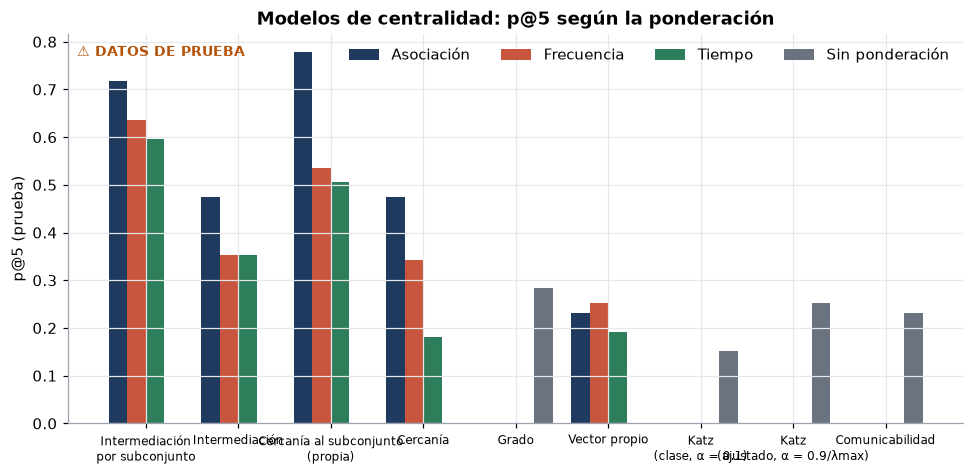

In [15]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
colores_peso = {"Asociación": COLOR["primario"], "Frecuencia": COLOR["acento"], "Tiempo": COLOR["verde"], "—": COLOR["gris"]}
orden_modelos = [CATALOGO[m][0] for m in CATALOGO]
ancho = 0.2
for j, (peso, col) in enumerate(colores_peso.items()):
    sub = t_cent_prueba[t_cent_prueba["Ponderación"] == peso].set_index("Modelo").reindex(orden_modelos)
    ax.bar(np.arange(len(orden_modelos)) + (j - 1.5) * ancho, sub.p5.fillna(0), ancho, color=col, label=peso if peso != "—" else "Sin ponderación")
ax.set_xticks(np.arange(len(orden_modelos)))
ax.set_xticklabels([textwrap_m for textwrap_m in [m.replace(" (", "\n(").replace("Intermediación por", "Intermediación\npor") for m in orden_modelos]], fontsize=8)
ax.set(ylabel="p@5 (prueba)", title="Modelos de centralidad: p@5 según la ponderación")
ax.legend(frameon=False, ncol=4, loc="upper right")
aviso_texto = "DATOS DE PRUEBA" if ES_PRUEBA else ""
if aviso_texto:
    ax.text(0.01, 0.97, "⚠ " + aviso_texto, transform=ax.transAxes, color="#B45309", fontsize=9, va="top", fontweight="bold")
guardar_figura(fig, "fig_centralidad_p5")

## 6. Modelo híbrido con node2vec

### 6.1 Idea del modelo

node2vec (Grover y Leskovec, 2016) aprende un vector por nodo: genera caminatas aleatorias sesgadas sobre el grafo y se las da a skip-gram
(word2vec) como si fueran “oraciones”. Dos parámetros controlan el sesgo de la caminata:

* **p** (retorno): $p$ bajo hace que la caminata regrese a menudo al nodo anterior → exploración **local** (tipo BFS, vecindades).
* **q** (entrada-salida): $q$ bajo empuja la caminata lejos del origen → exploración **profunda** (tipo DFS); $q$ alto la mantiene cerca.

Como en clase, la descripción se representa **sumando los vectores de sus lemas** y los candidatos son los nodos más cercanos por **similitud coseno**,
excluyendo las palabras de la descripción.

### 6.2 Dos cuidados de implementación

1. **El peso es una probabilidad, no un costo.** node2vec reparte la probabilidad de la siguiente arista **proporcionalmente al peso**
   (mayor peso = más probable). Los pesos de clase (`1/f`, `100 − FA`, `tiempo`) son *distancias*; usados tal cual, la caminata prefiere las
   asociaciones *más débiles*. Por eso se comparan: (a) el peso de clase `1/f`, (b) la **similitud** de cada ponderación y (c) sin pesos.
2. **Reproducibilidad.** `seed = 42`, un solo hilo (`workers = 1`) y una función hash estable para inicializar los vectores
   (la de Python cambia entre ejecuciones y vuelve el resultado irreproducible).

### 6.3 Variantes de representación de la descripción

La similitud coseno es invariante a la escala, así que **promedio y suma dan el mismo ranking**; no se comparan. Sí se comparan:
`suma` (clase), `suma normalizada` (cada vector a norma 1 antes de sumar, para que ningún lema domine por su magnitud) y `suma-IDF`
(cada lema pesa $\ln(|V| / (1 + \text{grado}))$: las palabras muy conectadas, poco informativas, pesan menos).

In [16]:
import zlib
from node2vec import Node2Vec

def hash_estable(texto):
    return zlib.crc32(texto.encode("utf-8"))

# Variantes de peso que se le pasan a node2vec (clave del atributo, descripción)
ESQUEMAS_N2V = {
    "d_frecuencia": "1/f (peso de clase, es distancia)",
    "s_frecuencia": "frecuencia (similitud)",
    "s_asociacion": "asociación (similitud)",
    "s_tiempo": "1/tiempo (similitud)",
    "uniforme": "sin pesos",
}
# Configuraciones (dimensión, longitud de caminata, nº de caminatas, p, q, ventana)
CONFIG_N2V = {
    "A_clase":   dict(dimensiones=300, longitud=80, caminatas=10, p=1.0, q=1.0, ventana=10),
    "B_128":     dict(dimensiones=128, longitud=30, caminatas=40, p=1.0, q=1.0, ventana=10),
    "C_local":   dict(dimensiones=128, longitud=30, caminatas=40, p=0.5, q=2.0, ventana=10),
    "D_profunda": dict(dimensiones=128, longitud=30, caminatas=40, p=2.0, q=0.5, ventana=10),
}
DIR_EMB = RESULTADOS / "embeddings"
DIR_EMB.mkdir(exist_ok=True)

def grafo_ponderado_n2v(esquema):
    H = nx.Graph()
    for a, b, d in G.edges(data=True):
        H.add_edge(a, b, weight=1.0 if esquema == "uniforme" else float(d[esquema]))
    return H

def entrenar_node2vec(cfg_id, esquema):
    """Entrena (o carga del disco) los embeddings de una configuración y un esquema de peso. Devuelve (matriz normalizada, nodos, segundos)."""
    from gensim.models import KeyedVectors
    c = CONFIG_N2V[cfg_id]
    ruta = DIR_EMB / f"n2v_{cfg_id}_{esquema}_{len(normas)}.kv"
    if ruta.exists():
        kv = KeyedVectors.load(str(ruta))
        seg = float(open(str(ruta) + ".t").read()) if Path(str(ruta) + ".t").exists() else float("nan")
    else:
        t0 = time.perf_counter()
        n2v = Node2Vec(grafo_ponderado_n2v(esquema), dimensions=c["dimensiones"], walk_length=c["longitud"], num_walks=c["caminatas"],
                       p=c["p"], q=c["q"], weight_key="weight", workers=1, quiet=True, seed=SEMILLA)
        modelo = n2v.fit(window=c["ventana"], min_count=1, batch_words=4, seed=SEMILLA, workers=1, hashfxn=hash_estable)
        kv, seg = modelo.wv, time.perf_counter() - t0
        kv.save(str(ruta)); open(str(ruta) + ".t", "w").write(str(seg))
    nodos = list(kv.index_to_key)
    M = kv.vectors / np.linalg.norm(kv.vectors, axis=1, keepdims=True)
    return M, nodos, kv, seg

def _entrena_uno(cfg_id, esquema):
    entrenar_node2vec(cfg_id, esquema)
    return cfg_id, esquema

def pre_entrenar(pares):
    """Entrena en paralelo (un proceso por modelo, cada uno con `workers=1` y la misma semilla) los embeddings que aún no existen en disco.
    El resultado no depende del paralelismo: cada modelo es determinista por sí solo."""
    from joblib import Parallel, delayed
    pendientes = [(c, e) for c, e in dict.fromkeys(pares) if not (DIR_EMB / f"n2v_{c}_{e}_{len(normas)}.kv").exists()]
    if pendientes:
        n_jobs = max(1, min(len(pendientes), (os.cpu_count() or 2) - 1, 5))
        print(f"Entrenando {len(pendientes)} modelos node2vec en paralelo ({n_jobs} procesos); tarda unos minutos…")
        Parallel(n_jobs=n_jobs)(delayed(_entrena_uno)(c, e) for c, e in pendientes)

GRADO = dict(G.degree())
IDF = {n: math.log(G.number_of_nodes() / (1 + GRADO[n])) for n in G.nodes}

def vector_descripcion(kv, utiles, agregacion):
    vs, ws = [], []
    for n in utiles:
        if n in kv.key_to_index:
            v = kv[n]
            if agregacion == "suma_normalizada":
                v = v / np.linalg.norm(v)
            vs.append(v); ws.append(IDF[n] if agregacion == "suma_idf" else 1.0)
    return None if not vs else np.sum([w * v for w, v in zip(ws, vs)], axis=0)

def correr_node2vec(cfg_id, esquema, agregacion, df=None):
    clave = (f"n2v|{cfg_id}|{agregacion}", esquema)
    NOMBRES[clave[0]] = (f"node2vec {cfg_id} · {agregacion.replace('_', ' ')}", "node2vec", "completo")
    if clave in RANKINGS:
        return clave
    df = EVAL if df is None else df
    t0 = time.perf_counter()
    M, nodos, kv, seg_entrenamiento = entrenar_node2vec(cfg_id, esquema)
    nodos_arr = np.array(nodos)
    salida = {}
    for fila in df.itertuples():
        q = vector_descripcion(kv, fila.utiles, agregacion)
        if q is None:
            salida[fila.id] = []; continue
        sims = M @ (q / np.linalg.norm(q))
        sims = {nodos[i]: float(sims[i]) for i in np.argpartition(-sims, min(300, len(sims) - 1))[:300]}
        salida[fila.id] = ordenar_candidatos(sims, set(fila.utiles))
    RANKINGS[clave], TIEMPOS[clave] = salida, seg_entrenamiento + (time.perf_counter() - t0)
    guardar_cache()
    return clave

### 6.4 Exploración de hiperparámetros (conjunto de **desarrollo**)

Primero se elige el esquema de peso con la configuración `B_128`; con el mejor esquema se comparan las cuatro configuraciones
(dimensión, p, q, longitud y número de caminatas) y las tres representaciones de la descripción. **La selección se hace solo con el conjunto de
desarrollo**; el de prueba se mira una vez al final. Los modelos se entrenan en paralelo (un proceso por modelo, `workers = 1`), por lo que el tiempo de
entrenamiento reportado incluye la competencia por CPU entre procesos concurrentes.

In [17]:
pre_entrenar([("B_128", e) for e in ESQUEMAS_N2V] + [("A_clase", "d_frecuencia")])
for _e in ESQUEMAS_N2V:
    NOMBRES.setdefault(f"n2v|B_128|suma", ("node2vec B_128 · suma", "node2vec", "completo"))
    correr_node2vec("B_128", _e, "suma")
aviso_prueba()
t_esq = tabla_resultados([(f"n2v|B_128|suma", e) for e in ESQUEMAS_N2V], DEV)
t_esq["Ponderación"] = [ESQUEMAS_N2V[e] for e in ESQUEMAS_N2V]
print("Desarrollo · configuración B_128 · suma · según el esquema de peso")
display(formato_tabla(t_esq))
MEJOR_ESQUEMA = t_esq.sort_values(["mrr", "p5"], ascending=False).iloc[0]["_clave"][1]
print("→ esquema elegido:", MEJOR_ESQUEMA, "(", ESQUEMAS_N2V[MEJOR_ESQUEMA], ")")

Desarrollo · configuración B_128 · suma · según el esquema de peso


Modelo,Grafo,Ponderación,p@1,p@3,p@5,MRR,Cobertura,Tiempo (s)
node2vec B_128 · suma,completo,"1/f (peso de clase, es distancia)",0.121,0.242,0.288,0.200,98.5%,230.2
node2vec B_128 · suma,completo,frecuencia (similitud),0.303,0.394,0.545,0.397,98.5%,220.5
node2vec B_128 · suma,completo,asociación (similitud),0.303,0.424,0.500,0.392,98.5%,220.8
node2vec B_128 · suma,completo,1/tiempo (similitud),0.212,0.364,0.439,0.323,98.5%,223.5
node2vec B_128 · suma,completo,sin pesos,0.258,0.424,0.500,0.374,98.5%,231.9


→ esquema elegido: s_frecuencia ( frecuencia (similitud) )


In [18]:
pre_entrenar([(c, MEJOR_ESQUEMA) for c in CONFIG_N2V])
for _c in CONFIG_N2V:
    for _agg in ("suma", "suma_normalizada", "suma_idf"):
        correr_node2vec(_c, MEJOR_ESQUEMA, _agg)
claves_cfg = [(f"n2v|{c}|{a}", MEJOR_ESQUEMA) for c in CONFIG_N2V for a in ("suma", "suma_normalizada", "suma_idf")]
t_cfg = tabla_resultados(claves_cfg, DEV)
aviso_prueba()
print(f"Desarrollo · esquema de peso «{MEJOR_ESQUEMA}» · configuraciones × representación")
display(formato_tabla(t_cfg))
_mejor = t_cfg.sort_values(["mrr", "p5"], ascending=False).iloc[0]["_clave"]
MEJOR_N2V = _mejor
print("→ mejor node2vec en desarrollo:", NOMBRES[_mejor[0]][0], "·", ESQUEMAS_N2V[_mejor[1]])
print("\nDescripción de las configuraciones:")
display(pd.DataFrame(CONFIG_N2V).T.rename(columns=dict(dimensiones="dimensión", longitud="longitud caminata", caminatas="nº caminatas", ventana="ventana")))
RES["node2vec"] = dict(esquema_elegido=MEJOR_ESQUEMA, mejor=list(MEJOR_N2V), configuraciones=CONFIG_N2V,
                       desarrollo_esquemas=t_esq.drop(columns="_clave").to_dict("records"),
                       desarrollo_configuraciones=t_cfg.drop(columns="_clave").to_dict("records"))

Desarrollo · esquema de peso «s_frecuencia» · configuraciones × representación


Modelo,Grafo,Ponderación,p@1,p@3,p@5,MRR,Cobertura,Tiempo (s)
node2vec A_clase · suma,completo,s_frecuencia,0.061,0.197,0.242,0.159,98.5%,170.8
node2vec A_clase · suma normalizada,completo,s_frecuencia,0.061,0.182,0.242,0.161,98.5%,170.8
node2vec A_clase · suma idf,completo,s_frecuencia,0.106,0.197,0.242,0.185,98.5%,170.8
node2vec B_128 · suma,completo,s_frecuencia,0.303,0.394,0.545,0.397,98.5%,220.5
node2vec B_128 · suma normalizada,completo,s_frecuencia,0.318,0.409,0.591,0.413,98.5%,220.5
node2vec B_128 · suma idf,completo,s_frecuencia,0.288,0.424,0.470,0.391,98.5%,220.5
node2vec C_local · suma,completo,s_frecuencia,0.258,0.348,0.500,0.356,98.5%,156.6
node2vec C_local · suma normalizada,completo,s_frecuencia,0.273,0.379,0.515,0.364,98.5%,156.6
node2vec C_local · suma idf,completo,s_frecuencia,0.227,0.364,0.500,0.337,98.5%,156.6
node2vec D_profunda · suma,completo,s_frecuencia,0.258,0.379,0.424,0.359,98.5%,162.2


→ mejor node2vec en desarrollo: node2vec B_128 · suma normalizada · frecuencia (similitud)

Descripción de las configuraciones:


,dimensión,longitud caminata,nº caminatas,p,q,ventana
A_clase,300.0,80.0,10.0,1.0,1.0,10.0
B_128,128.0,30.0,40.0,1.0,1.0,10.0
C_local,128.0,30.0,40.0,0.5,2.0,10.0
D_profunda,128.0,30.0,40.0,2.0,0.5,10.0


### 6.5 Resultado de node2vec en prueba

Se reporta en el conjunto de **prueba** (a) la configuración que el desarrollo eligió, (b) la configuración de clase (`A_clase`: 300 dimensiones y
**pesos de distancia 1/f**, tal como en la práctica) y (c) la misma configuración de clase con pesos de similitud. Así se aísla el efecto de cada decisión.

In [19]:
CLAVES_N2V_PRUEBA = [MEJOR_N2V, ("n2v|A_clase|suma", "d_frecuencia"), ("n2v|A_clase|suma", MEJOR_ESQUEMA)]
for _k in CLAVES_N2V_PRUEBA:
    correr_node2vec(_k[0].split("|")[1], _k[1], _k[0].split("|")[2])
t_n2v = tabla_resultados(CLAVES_N2V_PRUEBA, PRUEBA)
t_n2v["Ponderación"] = [ESQUEMAS_N2V[k[1]] for k in CLAVES_N2V_PRUEBA]
t_n2v["Modelo"] = [NOMBRES[k[0]][0] + (" ← elegido en desarrollo" if i == 0 else "") for i, k in enumerate(CLAVES_N2V_PRUEBA)]
aviso_prueba()
print("PRUEBA")
display(formato_tabla(t_n2v))

PRUEBA


Modelo,Grafo,Ponderación,p@1,p@3,p@5,MRR,Cobertura,Tiempo (s)
node2vec B_128 · suma normalizada ← elegido en desarrollo,completo,frecuencia (similitud),0.202,0.364,0.475,0.328,99.0%,220.5
node2vec A_clase · suma,completo,"1/f (peso de clase, es distancia)",0.081,0.172,0.212,0.155,99.0%,169.9
node2vec A_clase · suma,completo,frecuencia (similitud),0.040,0.131,0.222,0.130,99.0%,170.8


## 7. Extensiones: PageRank personalizado y fusión RRF

Modalidad C pide dos extensiones metodológicas sobre NAP. Se implementan estas, que además cubren el análisis de la dirección de las asociaciones:

### 7.1 Extensión 1 · PageRank personalizado, grafo no dirigido vs dirigido

**Idea.** Un lector que recorre el grafo y, con probabilidad $1-\alpha$, **reinicia en los lemas de la descripción** termina pasando más tiempo en
las palabras bien conectadas con *todos* ellos. Es el PageRank personalizado (caminata aleatoria con reinicio):
$\;\pi = \alpha\,\pi P + (1-\alpha)\,v$, con $v$ uniforme sobre los lemas de la descripción y $\alpha = 0.85$.

* Usa **similitud** como peso (la probabilidad de seguir una arista es proporcional a ella), no distancia.
* **No dirigido**: la arista $\{a, b\}$ se recorre en ambos sentidos.
* **Dirigido**: se respeta la dirección del experimento, **estímulo → respuesta**. Una palabra solo recibe masa si alguien la dio como respuesta
  a otra. Las respuestas que no fueron estímulo (≈ 94 % de los nodos) no tienen aristas de salida; su masa se redistribuye según el vector de reinicio (*dangling nodes*).
* También se prueba la dirección **inversa** (respuesta → estímulo), que modela “de la respuesta recuerdo el estímulo”: justo lo que ocurre al
  describir un concepto con sus asociados (*miel*, *picar*, *flor* → **abeja**).

In [20]:
D_inv = D.reverse(copy=True)
GRAFOS_PPR = {"no_dirigido": G, "dirigido": D, "dirigido_inverso": D_inv}
NOMBRE_PPR = {"no_dirigido": "PageRank personalizado · no dirigido", "dirigido": "PageRank personalizado · dirigido (estímulo→respuesta)",
              "dirigido_inverso": "PageRank personalizado · dirigido inverso (respuesta→estímulo)"}
for _k, _v in NOMBRE_PPR.items():
    NOMBRES[f"ppr_{_k}"] = (_v, "Extensión 1", "completo")

def correr_ppr(variante, peso, alfa=0.85, df=None):
    clave = (f"ppr_{variante}" + ("" if alfa == 0.85 else f"_a{alfa}"), peso)
    NOMBRES.setdefault(clave[0], (f"{NOMBRE_PPR[variante]} (α={alfa})", "Extensión 1", "completo"))
    if clave in RANKINGS:
        return clave
    df, grafo = (EVAL if df is None else df), GRAFOS_PPR[variante]
    salida, t0 = {}, time.perf_counter()
    for fila in df.itertuples():
        u = [n for n in fila.utiles if n in grafo]
        if not u:
            salida[fila.id] = []; continue
        pers = {n: 1.0 / len(u) for n in u}
        puntajes = nx.pagerank(grafo, alpha=alfa, personalization=pers, weight=f"s_{peso}", dangling=pers, max_iter=200, tol=1e-9)
        salida[fila.id] = ordenar_candidatos(puntajes, set(fila.utiles))
    RANKINGS[clave], TIEMPOS[clave] = salida, time.perf_counter() - t0
    guardar_cache()
    return clave

for _v in GRAFOS_PPR:
    for _p in PONDERACIONES:
        correr_ppr(_v, _p)
PLAN_PPR = [(f"ppr_{v}", p) for v in GRAFOS_PPR for p in PONDERACIONES]
aviso_prueba()
print("DESARROLLO")
display(formato_tabla(tabla_resultados(PLAN_PPR, DEV)))

DESARROLLO


Modelo,Grafo,Ponderación,p@1,p@3,p@5,MRR,Cobertura,Tiempo (s)
PageRank personalizado · no dirigido,completo,Asociación,0.500,0.682,0.742,0.611,98.5%,4.0
PageRank personalizado · no dirigido,completo,Frecuencia,0.500,0.667,0.742,0.613,98.5%,4.1
PageRank personalizado · no dirigido,completo,Tiempo,0.333,0.500,0.621,0.458,98.5%,4.1
PageRank personalizado · dirigido (estímulo→respuesta),completo,Asociación,0.061,0.106,0.106,0.097,98.5%,2.9
PageRank personalizado · dirigido (estímulo→respuesta),completo,Frecuencia,0.061,0.106,0.106,0.097,98.5%,2.8
PageRank personalizado · dirigido (estímulo→respuesta),completo,Tiempo,0.000,0.015,0.030,0.024,98.5%,2.8
PageRank personalizado · dirigido inverso (respuesta→estímulo),completo,Asociación,0.485,0.621,0.727,0.585,98.5%,4.1
PageRank personalizado · dirigido inverso (respuesta→estímulo),completo,Frecuencia,0.455,0.621,0.742,0.568,98.5%,3.3
PageRank personalizado · dirigido inverso (respuesta→estímulo),completo,Tiempo,0.318,0.515,0.561,0.444,98.5%,3.1


**Sensibilidad al factor de reinicio $\alpha$.** $\alpha$ pequeño = reinicia seguido (se queda cerca de los lemas); $\alpha$ grande = explora lejos.
Se elige en **desarrollo**, con la mejor ponderación del bloque anterior.

In [21]:
_t = tabla_resultados(PLAN_PPR, DEV)
_mejor_ppr = _t.sort_values(["mrr", "p5"], ascending=False).iloc[0]["_clave"]
MEJOR_PPR_VARIANTE, MEJOR_PPR_PESO = _mejor_ppr[0].replace("ppr_", ""), _mejor_ppr[1]
filas_alfa = []
for _a in (0.5, 0.7, 0.85, 0.95):
    _k = correr_ppr(MEJOR_PPR_VARIANTE, MEJOR_PPR_PESO, _a)
    filas_alfa.append({"α": _a, **evaluar_clave(_k, DEV)})
t_alfa = pd.DataFrame(filas_alfa)
ALFA_ELEGIDA = float(t_alfa.sort_values(["mrr", "p5"], ascending=False).iloc[0]["α"])
display(t_alfa.rename(columns={"p1": "p@1", "p3": "p@3", "p5": "p@5", "mrr": "MRR", "cobertura": "Cobertura"}).style.hide(axis="index").format(
    {"p@1": "{:.3f}", "p@3": "{:.3f}", "p@5": "{:.3f}", "MRR": "{:.3f}", "Cobertura": "{:.1%}"}).background_gradient(subset=["MRR"], cmap="Blues"))
print(f"→ en desarrollo, la mejor variante es «{MEJOR_PPR_VARIANTE}» con ponderación «{MEJOR_PPR_PESO}» y α = {ALFA_ELEGIDA}")
RES["pagerank"] = dict(variante=MEJOR_PPR_VARIANTE, peso=MEJOR_PPR_PESO, alfa=ALFA_ELEGIDA, sensibilidad_alfa=t_alfa.to_dict("records"))

α,p@1,p@3,p@5,MRR,Cobertura,n
0.500000,0.515,0.697,0.773,0.627,98.5%,66
0.700000,0.515,0.697,0.773,0.630,98.5%,66
0.850000,0.500,0.667,0.742,0.613,98.5%,66
0.950000,0.439,0.652,0.682,0.553,98.5%,66


→ en desarrollo, la mejor variante es «no_dirigido» con ponderación «frecuencia» y α = 0.7


### 7.2 Extensión 2 · Fusión de rankings (*Reciprocal Rank Fusion*)

Los modelos de grafos y node2vec se equivocan de formas distintas: los primeros miran **caminos cortos** entre las palabras de la descripción;
el segundo, **vecindades estructurales** aprendidas. La fusión RRF (Cormack et al., 2009) combina listas ordenadas sin necesitar que los puntajes
sean comparables:

$$\text{RRF}(w) \;=\; \sum_{m\in\mathcal M}\frac{1}{k + \text{rango}_m(w)}$$

donde $\text{rango}_m(w)$ es la posición de $w$ en la lista del modelo $m$ y $k$ amortigua el peso de los primeros lugares. Se fusionan
el **mejor modelo de centralidad**, el **mejor node2vec** y el **mejor PageRank personalizado**, todos elegidos **en desarrollo**; también se prueban
las parejas. $k$ se ajusta en desarrollo.

In [22]:
def mejor_en_desarrollo(claves):
    t = tabla_resultados(claves, DEV)
    return t.sort_values(["mrr", "p5", "p1"], ascending=False).iloc[0]["_clave"]

CLAVES_CENT = [k for k in PLAN_CENTRALIDAD if k[0] not in ("katz_clase",)]
MEJOR_CENT = mejor_en_desarrollo(CLAVES_CENT)
MEJOR_PPR = (f"ppr_{MEJOR_PPR_VARIANTE}" + ("" if ALFA_ELEGIDA == 0.85 else f"_a{ALFA_ELEGIDA}"), MEJOR_PPR_PESO)
print("Componentes de la fusión (elegidos en desarrollo):")
for _n, _k in (("centralidad", MEJOR_CENT), ("node2vec", MEJOR_N2V), ("PageRank", MEJOR_PPR)):
    print(f"  · {_n:<12}: {NOMBRES[_k[0]][0]}  ·  {ETIQUETA_PESO.get(_k[1], ESQUEMAS_N2V.get(_k[1], _k[1]))}")

def fusion_rrf(claves, k, tope=TOP_K_CANDIDATOS, pesos=None):
    ids = RANKINGS[claves[0]].keys()
    salida = {}
    for i in ids:
        puntaje = collections.defaultdict(float)
        for j, clave in enumerate(claves):
            for rango, w in enumerate(RANKINGS[clave].get(i, []), start=1):
                puntaje[w] += (1.0 if pesos is None else pesos[j]) / (k + rango)
        salida[i] = [w for _, w in heapq.nsmallest(tope, ((-round(v, 12), w) for w, v in puntaje.items()))]
    return salida

RRF_COMP = {}     # clave de la fusión → (claves de los modelos que fusiona, k); lo usa la demostración en vivo (§11)

def registrar_rrf(nombre, claves, k):
    clave = (f"rrf|{nombre}", f"k={k}")
    RRF_COMP[clave] = (list(claves), k)
    if clave not in RANKINGS:
        RANKINGS[clave] = fusion_rrf(claves, k)
        TIEMPOS[clave] = sum(TIEMPOS.get(c, 0) for c in claves)
    NOMBRES[clave[0]] = (f"Fusión RRF · {nombre}", "Extensión 2", "completo")
    ETIQUETA_PESO[clave[1]] = clave[1]
    return clave

COMBINACIONES = {"centralidad + node2vec": [MEJOR_CENT, MEJOR_N2V], "centralidad + PageRank": [MEJOR_CENT, MEJOR_PPR],
                 "node2vec + PageRank": [MEJOR_N2V, MEJOR_PPR], "centralidad + node2vec + PageRank": [MEJOR_CENT, MEJOR_N2V, MEJOR_PPR]}
filas_k, claves_k = [], {}
for _nombre, _cl in COMBINACIONES.items():
    for _k in (10, 30, 60, 100):
        _c = registrar_rrf(_nombre, _cl, _k)
        claves_k[(_nombre, _k)] = _c
        filas_k.append({"Combinación": _nombre, "k": _k, **evaluar_clave(_c, DEV)})
t_k = pd.DataFrame(filas_k)
aviso_prueba()
print("DESARROLLO · efecto de k")
display(t_k.rename(columns={"p1": "p@1", "p3": "p@3", "p5": "p@5", "mrr": "MRR", "cobertura": "Cobertura"}).style.hide(axis="index").format(
    {"p@1": "{:.3f}", "p@3": "{:.3f}", "p@5": "{:.3f}", "MRR": "{:.3f}", "Cobertura": "{:.1%}"}).background_gradient(subset=["MRR"], cmap="Blues"))
_mejor_fila = t_k.sort_values(["mrr", "p5"], ascending=False).iloc[0]
MEJOR_RRF = claves_k[(_mejor_fila["Combinación"], int(_mejor_fila["k"]))]
print(f"→ mejor fusión en desarrollo: {_mejor_fila['Combinación']} con k = {int(_mejor_fila['k'])}")
guardar_cache()
RES["rrf"] = dict(combinacion=_mejor_fila["Combinación"], k=int(_mejor_fila["k"]), componentes={n: list(c) for n, c in (("centralidad", MEJOR_CENT), ("node2vec", MEJOR_N2V), ("pagerank", MEJOR_PPR))},
                  desarrollo=t_k.to_dict("records"))

Componentes de la fusión (elegidos en desarrollo):
  · centralidad : Cercanía al subconjunto (propia)  ·  Asociación
  · node2vec    : node2vec B_128 · suma normalizada  ·  frecuencia (similitud)
  · PageRank    : PageRank personalizado · no dirigido (α=0.7)  ·  Frecuencia


DESARROLLO · efecto de k


Combinación,k,p@1,p@3,p@5,MRR,Cobertura,n
centralidad + node2vec,10,0.591,0.742,0.758,0.668,98.5%,66
centralidad + node2vec,30,0.591,0.727,0.788,0.669,98.5%,66
centralidad + node2vec,60,0.591,0.727,0.788,0.669,98.5%,66
centralidad + node2vec,100,0.591,0.727,0.788,0.671,98.5%,66
centralidad + PageRank,10,0.606,0.758,0.788,0.698,98.5%,66
centralidad + PageRank,30,0.606,0.758,0.788,0.699,98.5%,66
centralidad + PageRank,60,0.606,0.758,0.788,0.699,98.5%,66
centralidad + PageRank,100,0.606,0.758,0.788,0.698,98.5%,66
node2vec + PageRank,10,0.591,0.712,0.773,0.665,98.5%,66
node2vec + PageRank,30,0.591,0.697,0.758,0.661,98.5%,66


→ mejor fusión en desarrollo: centralidad + PageRank con k = 60


## 8. Evaluación comparativa

### 8.1 Tabla comparativa única (conjunto de **prueba**)

Todos los modelos y ponderaciones en una sola tabla, con las mismas descripciones, el mismo preprocesamiento y las mismas métricas
(p@1, p@3, p@5, MRR y cobertura). Las decisiones (mejor node2vec, $\alpha$ de PageRank, $k$ de RRF, mejor centralidad) se tomaron **solo en desarrollo**.
Debajo de cada cifra clave se reporta el **intervalo de confianza al 95 %** por *bootstrap* sobre las descripciones, porque con pocas descripciones
las diferencias pequeñas no son significativas.

In [23]:
def mejor_k_rrf(nombre):
    t = t_k[t_k["Combinación"] == nombre].sort_values(["mrr", "p5"], ascending=False)
    return claves_k[(nombre, int(t.iloc[0]["k"]))]

CLAVES_TABLA = (list(PLAN_CENTRALIDAD)
                + [k for k in CLAVES_N2V_PRUEBA]
                + [(f"ppr_{v}", p) for v in GRAFOS_PPR for p in PONDERACIONES]
                + [MEJOR_PPR]
                + [mejor_k_rrf(n) for n in COMBINACIONES])
CLAVES_TABLA = list(dict.fromkeys(CLAVES_TABLA))
t_unica = tabla_resultados(CLAVES_TABLA, PRUEBA)
t_unica_dev = tabla_resultados(CLAVES_TABLA, DEV)
t_unica["p5_dev"], t_unica["mrr_dev"] = t_unica_dev.p5.values, t_unica_dev.mrr.values

def bootstrap_ic(clave, df, metrica, n=2000):
    r = RANKINGS[clave]
    v = np.array([metricas_lista(r.get(f.id, []), f.nodo)[metrica] for f in df.itertuples()], dtype=float)
    rng = np.random.RandomState(SEMILLA)
    medias = [v[rng.randint(0, len(v), len(v))].mean() for _ in range(n)]
    return np.percentile(medias, [2.5, 97.5])

ic = [bootstrap_ic(k, PRUEBA, "p5") for k in t_unica["_clave"]]
t_unica["p5_ic"] = [f"[{a:.2f}, {b:.2f}]" for a, b in ic]
orden_familia = {"Centralidad": 0, "node2vec": 1, "Extensión 1": 2, "Extensión 2": 3}
t_unica["_o"] = t_unica.Familia.map(orden_familia)
t_unica = t_unica.sort_values(["_o", "mrr"], ascending=[True, False]).drop(columns="_o").reset_index(drop=True)

aviso_prueba()
vis = t_unica[["Familia", "Modelo", "Grafo", "Ponderación", "p1", "p3", "p5", "p5_ic", "mrr", "cobertura", "Tiempo (s)"]].rename(
    columns={"p1": "p@1", "p3": "p@3", "p5": "p@5", "p5_ic": "IC 95 % de p@5", "mrr": "MRR", "cobertura": "Cobertura"})
display(vis.style.hide(axis="index").format({"p@1": "{:.3f}", "p@3": "{:.3f}", "p@5": "{:.3f}", "MRR": "{:.3f}", "Cobertura": "{:.1%}", "Tiempo (s)": "{:.1f}"})
        .background_gradient(subset=["p@1", "p@3", "p@5", "MRR"], cmap="Blues", vmin=0, vmax=max(0.5, float(vis[["p@1", "p@3", "p@5", "MRR"]].max().max())))
        .set_properties(subset=["Modelo"], **{"text-align": "left"}))
t_unica.drop(columns="_clave").to_csv(RESULTADOS / "tabla_comparativa.csv", index=False, encoding="utf-8-sig")
RES["tabla_unica"] = t_unica.drop(columns="_clave").to_dict("records")

Familia,Modelo,Grafo,Ponderación,p@1,p@3,p@5,IC 95 % de p@5,MRR,Cobertura,Tiempo (s)
Centralidad,Cercanía al subconjunto (propia),completo,Asociación,0.515,0.758,0.778,"[0.70, 0.85]",0.648,99.0%,8.2
Centralidad,Intermediación por subconjunto,completo,Asociación,0.495,0.636,0.717,"[0.63, 0.80]",0.586,96.0%,15.6
Centralidad,Intermediación por subconjunto,completo,Tiempo,0.384,0.556,0.596,"[0.49, 0.69]",0.477,97.0%,18.1
Centralidad,Intermediación por subconjunto,completo,Frecuencia,0.323,0.505,0.636,"[0.54, 0.73]",0.443,97.0%,28.7
Centralidad,Cercanía al subconjunto (propia),completo,Tiempo,0.374,0.414,0.505,"[0.40, 0.61]",0.436,99.0%,8.6
Centralidad,Cercanía al subconjunto (propia),completo,Frecuencia,0.232,0.424,0.535,"[0.43, 0.64]",0.359,99.0%,8.8
Centralidad,Intermediación,reducido,Asociación,0.131,0.384,0.475,"[0.38, 0.58]",0.299,96.0%,29.8
Centralidad,Cercanía,reducido,Asociación,0.152,0.343,0.475,"[0.37, 0.57]",0.299,99.0%,26.4
Centralidad,Cercanía,reducido,Frecuencia,0.131,0.212,0.343,"[0.25, 0.43]",0.242,99.0%,27.8
Centralidad,Intermediación,reducido,Frecuencia,0.091,0.232,0.354,"[0.26, 0.44]",0.217,94.9%,30.9


### 8.2 Comparación con la Tabla 1 del proyecto

La Tabla 1 resume los resultados de clase con **otro conjunto de evaluación** (276 descripciones de 56 conceptos, del profesor). Nuestras cifras salen de
**descripciones nuevas** y de un grafo ligeramente limpio, por lo que la comparación es **orientativa** y no una prueba de mejora: sirve para ver si
el orden entre modelos se conserva. (En el cuaderno de clase la celda de intermediación por subconjunto con asociación imprimió p@1 = .264, p@3 = .406, p@5 = .446,
frente a .246 / .406 / .438 de la Tabla 1; se usa la Tabla 1.)

Modelo,Ponderación,p@1 clase,p@1 nuestro,p@3 clase,p@3 nuestro,p@5 clase,p@5 nuestro
Intermediación por subconjunto,Asociación,0.246,0.509,0.406,0.642,0.438,0.715
Intermediación por subconjunto,Frecuencia,0.178,0.358,0.312,0.539,0.377,0.624
Intermediación por subconjunto,Tiempo,0.112,0.370,0.199,0.497,0.250,0.527
"Intermediación, grafo reducido",Asociación,0.159,0.145,0.344,0.418,0.431,0.545
"Cercanía, grafo reducido",Asociación,0.221,0.176,0.428,0.364,0.518,0.491
"Cercanía, grafo reducido",Frecuencia,0.196,0.164,0.355,0.255,0.514,0.358
"Comunicabilidad, grafo reducido",Asociación,0.116,0.079,0.228,0.200,0.319,0.285
"Grado, grafo reducido",Asociación,0.109,0.109,0.239,0.236,0.362,0.339
"Vector propio, grafo reducido",Asociación,0.112,0.127,0.221,0.182,0.268,0.285
"Katz, grafo reducido",Asociación,0.091,0.048,0.149,0.145,0.192,0.164


Correlación de Spearman entre el orden de los modelos en la Tabla 1 y el nuestro (p@5): 0.55


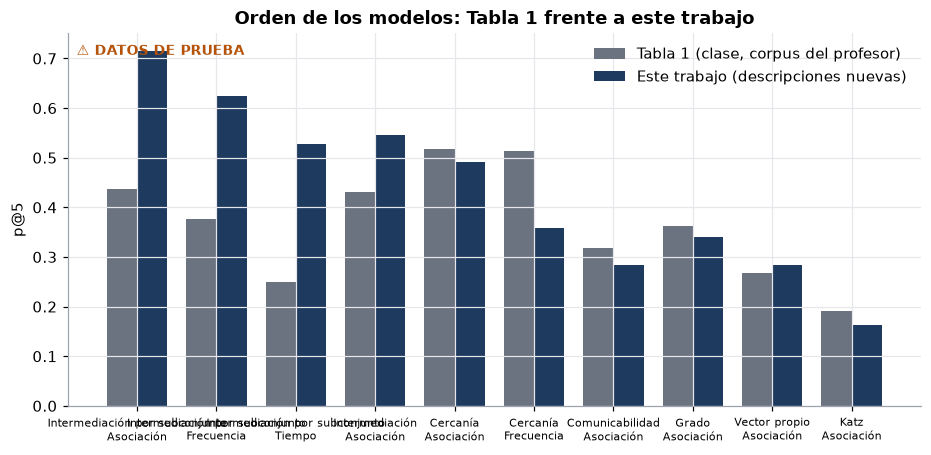

In [24]:
TABLA1 = [  # (modelo, ponderación, p@1, p@3, p@5, clave nuestra)
    ("Intermediación por subconjunto", "Asociación", .246, .406, .438, ("bet_subconjunto", "asociacion")),
    ("Intermediación por subconjunto", "Frecuencia", .178, .312, .377, ("bet_subconjunto", "frecuencia")),
    ("Intermediación por subconjunto", "Tiempo", .112, .199, .250, ("bet_subconjunto", "tiempo")),
    ("Intermediación, grafo reducido", "Asociación", .159, .344, .431, ("bet_reducido", "asociacion")),
    ("Cercanía, grafo reducido", "Asociación", .221, .428, .518, ("cercania_reducido", "asociacion")),
    ("Cercanía, grafo reducido", "Frecuencia", .196, .355, .514, ("cercania_reducido", "frecuencia")),
    ("Comunicabilidad, grafo reducido", "Asociación", .116, .228, .319, ("comunicabilidad_reducido", "—")),
    ("Grado, grafo reducido", "Asociación", .109, .239, .362, ("grado_reducido", "—")),
    ("Vector propio, grafo reducido", "Asociación", .112, .221, .268, ("vector_propio_reducido", "asociacion")),
    ("Katz, grafo reducido", "Asociación", .091, .149, .192, ("katz_clase", "—")),
]
filas = []
for nombre, peso, a, b, c, clave in TABLA1:
    ev_ = evaluar_clave(clave, EVAL)           # se compara con el total de descripciones válidas
    filas.append({"Modelo": nombre, "Ponderación": peso, "p@1 clase": a, "p@1 nuestro": ev_["p1"], "p@3 clase": b, "p@3 nuestro": ev_["p3"],
                  "p@5 clase": c, "p@5 nuestro": ev_["p5"]})
t_ref = pd.DataFrame(filas)
aviso_prueba()
display(t_ref.style.hide(axis="index").format({c: "{:.3f}" for c in t_ref.columns[2:]}))
rho = pd.Series(t_ref["p@5 clase"].values).corr(pd.Series(t_ref["p@5 nuestro"].values), method="spearman")
print(f"Correlación de Spearman entre el orden de los modelos en la Tabla 1 y el nuestro (p@5): {rho:.2f}")
RES["tabla1_comparacion"] = dict(filas=t_ref.to_dict("records"), spearman_p5=float(rho))

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(t_ref)); ancho = 0.38
ax.bar(x - ancho / 2, t_ref["p@5 clase"], ancho, color=COLOR["gris"], label="Tabla 1 (clase, corpus del profesor)")
ax.bar(x + ancho / 2, t_ref["p@5 nuestro"], ancho, color=COLOR["primario"], label="Este trabajo (descripciones nuevas)")
ax.set_xticks(x); ax.set_xticklabels([f"{m.split(',')[0]}\n{p}" for m, p in zip(t_ref.Modelo, t_ref["Ponderación"])], fontsize=7, rotation=0)
ax.set(ylabel="p@5", title="Orden de los modelos: Tabla 1 frente a este trabajo"); ax.legend(frameon=False)
if ES_PRUEBA:
    ax.text(0.01, 0.97, "⚠ DATOS DE PRUEBA", transform=ax.transAxes, color="#B45309", fontsize=9, va="top", fontweight="bold")
guardar_figura(fig, "fig_tabla1_vs_nuestro")

### 8.3 ¿Dónde gana cada enfoque?

Se separan las descripciones de prueba según qué enfoque coloca la palabra objetivo entre los **5 primeros**: el mejor modelo de grafos
(centralidad o PageRank, elegido en desarrollo), el mejor node2vec, ambos o ninguno. Luego se compara qué rasgos tienen esas descripciones.

In [25]:
MEJOR_GRAFO = mejor_en_desarrollo(CLAVES_CENT + [(f"ppr_{v}", p) for v in GRAFOS_PPR for p in PONDERACIONES])
print("Mejor modelo de grafos (desarrollo):", NOMBRES[MEJOR_GRAFO[0]][0], "·", ETIQUETA_PESO.get(MEJOR_GRAFO[1], MEJOR_GRAFO[1]))
print("Mejor node2vec (desarrollo)        :", NOMBRES[MEJOR_N2V[0]][0], "·", ESQUEMAS_N2V[MEJOR_N2V[1]])
P = PRUEBA.copy()
P["pos_grafo"] = [metricas_lista(RANKINGS[MEJOR_GRAFO].get(f.id, []), f.nodo)["pos"] for f in P.itertuples()]
P["pos_n2v"] = [metricas_lista(RANKINGS[MEJOR_N2V].get(f.id, []), f.nodo)["pos"] for f in P.itertuples()]
P["ok_grafo"] = P.pos_grafo.map(lambda x: x is not None and x <= 5)
P["ok_n2v"] = P.pos_n2v.map(lambda x: x is not None and x <= 5)
P["gana"] = np.select([P.ok_grafo & P.ok_n2v, P.ok_grafo, P.ok_n2v], ["ambos", "solo grafos", "solo node2vec"], "ninguno")
P["n_utiles"] = P.utiles.map(len)
P["grado_obj"] = P.nodo.map(GRADO)
P["es_estimulo"] = P.nodo.isin(ESTIMULOS)
P["idf_medio"] = P.utiles.map(lambda u: np.mean([IDF[n] for n in u]) if u else np.nan)
resumen_gana = (P.groupby("gana").agg(descripciones=("id", "size"), lemas_utiles=("n_utiles", "mean"), grado_del_objetivo=("grado_obj", "median"),
                                      idf_medio_lemas=("idf_medio", "mean")).reindex(["ambos", "solo grafos", "solo node2vec", "ninguno"]))
aviso_prueba()
display(resumen_gana.style.format({"lemas_utiles": "{:.1f}", "grado_del_objetivo": "{:.0f}", "idf_medio_lemas": "{:.2f}"}))
RES["quien_gana"] = {k: int(v) for k, v in P.gana.value_counts().items()}
RES["quien_gana_rasgos"] = resumen_gana.reset_index().to_dict("records")

Mejor modelo de grafos (desarrollo): Cercanía al subconjunto (propia) · Asociación
Mejor node2vec (desarrollo)        : node2vec B_128 · suma normalizada · frecuencia (similitud)


,descripciones,lemas_utiles,grado_del_objetivo,idf_medio_lemas
gana,,,,
ambos,45,4.3,62,5.98
solo grafos,32,4.0,61,5.70
solo node2vec,2,4.0,62,5.05
ninguno,20,3.4,66,6.03


### 8.4 Efecto de limpiar NAP (pregunta guía 4)

El grafo de clase conserva el nodo `=` (respuestas inválidas), números y marcas de tiempo, y cuando dos respuestas comparten lema la última
**sobrescribe** a la primera. Se reconstruye ese grafo tal como lo hace el cuaderno de clase y se evalúan con él dos modelos, para medir qué tanto
cambian los resultados.

In [26]:
def construye_grafo_clase(ruta):
    """Réplica fiel de `Construye_Grafo` del cuaderno de clase, solo con ponderación de asociación (100 − FA)."""
    import xlrd
    hoja = xlrd.open_workbook(str(ruta)).sheet_by_index(0)
    Gc, estimulo = nx.Graph(), ""
    for fila in range(0, hoja.nrows - 1):
        cadena = hoja.cell(fila, 0).value
        if cadena == "--PALABRAS--":
            continue
        elif cadena == "======":
            estimulo = hoja.cell(fila + 1, 4).value
        elif cadena == "" or cadena == "=":
            continue
        elif hoja.cell(fila, 2).value == "":
            continue
        else:
            lema = str(hoja.cell(fila, 4).value).strip()
            Gc.add_edge(str(estimulo).strip(), lema, d_asociacion=100 - float(hoja.cell(fila, 3).value))
    return Gc

if RUTA_XLS.exists():
    G_clase = construye_grafo_clase(RUTA_XLS)
    print(f"Grafo de clase: {G_clase.number_of_nodes():,} nodos / {G_clase.number_of_edges():,} aristas · "
          f"nuestro grafo limpio: {G.number_of_nodes():,} / {G.number_of_edges():,}")
    print(f"Grado del nodo basura '=' en el grafo de clase: {G_clase.degree('=') if '=' in G_clase else 0}")
    filas_c = []
    for _m, _f in (("bet_subconjunto", m_bet_subconjunto), ("cercania_reducido", m_cercania_reducido)):
        for etiqueta, grafo in (("grafo de clase (sin limpiar)", G_clase), ("grafo limpio (este trabajo)", G)):
            r = {}
            for f in tqdm(EVAL.itertuples(), total=len(EVAL), desc=f"{_m} · {etiqueta}", leave=False):
                u = [n for n in f.utiles if n in grafo]
                r[f.id] = ordenar_candidatos(_f(grafo, u, "asociacion"), set(u)) if u else []
            m = pd.DataFrame([metricas_lista(r[f.id], f.nodo) for f in EVAL.itertuples()])
            filas_c.append({"Modelo": CATALOGO[_m][0], "Grafo": etiqueta, "p@1": m.p1.mean(), "p@3": m.p3.mean(), "p@5": m.p5.mean(), "MRR": m.rr.mean()})
    t_limpieza = pd.DataFrame(filas_c)
    aviso_prueba()
    display(t_limpieza.style.hide(axis="index").format({c: "{:.3f}" for c in ("p@1", "p@3", "p@5", "MRR")}))
    RES["efecto_limpieza"] = dict(nodo_basura_grado=int(G_clase.degree("=")) if "=" in G_clase else 0, filas=t_limpieza.to_dict("records"))
guardar_resultados()

Grafo de clase: 4,239 nodos / 12,872 aristas · nuestro grafo limpio: 4,222 / 12,834


Grado del nodo basura '=' en el grafo de clase: 4


bet_subconjunto · grafo de clase (sin limpiar):   0%|          | 0/165 [00:00<?, ?it/s]

bet_subconjunto · grafo limpio (este trabajo):   0%|          | 0/165 [00:00<?, ?it/s]

cercania_reducido · grafo de clase (sin limpiar):   0%|          | 0/165 [00:00<?, ?it/s]

cercania_reducido · grafo limpio (este trabajo):   0%|          | 0/165 [00:00<?, ?it/s]

Modelo,Grafo,p@1,p@3,p@5,MRR
Intermediación por subconjunto,grafo de clase (sin limpiar),0.521,0.655,0.715,0.604
Intermediación por subconjunto,grafo limpio (este trabajo),0.509,0.642,0.715,0.596
Cercanía,grafo de clase (sin limpiar),0.170,0.352,0.479,0.321
Cercanía,grafo limpio (este trabajo),0.176,0.364,0.491,0.323


## 9. Análisis de errores

Se analizan los casos de **prueba** en que el **mejor modelo** no coloca la palabra objetivo entre los 5 primeros. El mejor modelo se elige en
**desarrollo** entre todos los de la tabla (incluidas las fusiones). Cada error se clasifica con una **regla automática** a partir de lo observable
(lemas útiles, lemas fuera del grafo, grado, distancia) y deja una columna `causa_revisada` para que el equipo **confirme o corrija a mano**: las reglas
son una primera clasificación, no un veredicto.

| Causa | Regla automática |
|---|---|
| **Sin información en el grafo** | la descripción no tiene ningún lema útil, o ≥ 60 % de sus lemas está fuera del grafo |
| **Lematización** | un lema fuera del grafo es prefijo (≥ 4 letras) de un nodo: la raíz quedó truncada (*cáscar* → *cáscara*) |
| **Palabra objetivo poco conectada** | el objetivo tiene grado ≤ 3 o está a más de 3 saltos de todos los lemas útiles |
| **Sesgo hacia nodos muy conectados** | el grado medio de los 5 candidatos es ≥ 4× el grado del objetivo |
| **Descripción genérica o ambigua** | los lemas útiles son palabras muy conectadas (IDF medio bajo) o hay un candidato casi sinónimo (comparte vecinos con el objetivo) |
| **Otra** | no cumple ninguna regla; requiere revisión humana (p. ej. polisemia) |

Mejor modelo en desarrollo: Fusión RRF · centralidad + PageRank · k=60


  prueba → p@1 0.596 · p@3 0.768 · p@5 0.838 · MRR 0.705
Errores en prueba (palabra objetivo fuera del top 5): 16 de 99 descripciones.


,casos,%
causa_sugerida,,
Lematización,7,44%
Sin información en el grafo,5,31%
Descripción genérica o ambigua,3,19%
Otra (revisar),1,6%


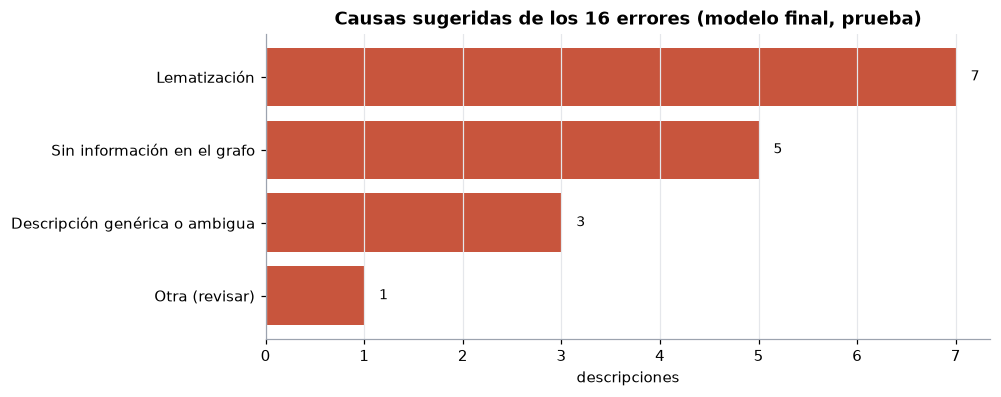

In [27]:
import bisect

_candidatos_mejor = CLAVES_TABLA
MODELO_FINAL = mejor_en_desarrollo(_candidatos_mejor)
print("Mejor modelo en desarrollo:", NOMBRES[MODELO_FINAL[0]][0], "·", ETIQUETA_PESO.get(MODELO_FINAL[1], ESQUEMAS_N2V.get(MODELO_FINAL[1], MODELO_FINAL[1])))
ev_final_prueba, ev_final_dev = evaluar_clave(MODELO_FINAL, PRUEBA), evaluar_clave(MODELO_FINAL, DEV)
aviso_prueba()
print(f"  prueba → p@1 {ev_final_prueba['p1']:.3f} · p@3 {ev_final_prueba['p3']:.3f} · p@5 {ev_final_prueba['p5']:.3f} · MRR {ev_final_prueba['mrr']:.3f}")
RES["modelo_final"] = dict(clave=list(MODELO_FINAL), nombre=NOMBRES[MODELO_FINAL[0]][0], prueba=ev_final_prueba, desarrollo=ev_final_dev)

_nodos_ord = sorted(NODOS)
def hay_nodo_con_prefijo(prefijo):
    i = bisect.bisect_left(_nodos_ord, prefijo)
    return i < len(_nodos_ord) and _nodos_ord[i].startswith(prefijo) and _nodos_ord[i] != prefijo

def distancia_minima(objetivo, utiles):
    if not utiles:
        return None
    d = nx.single_source_shortest_path_length(G, objetivo, cutoff=4)
    return min((d[u] for u in utiles if u in d), default=None)

def vecinos_comunes(a, b):
    na, nb = set(G[a]), set(G[b])
    return len(na & nb) / max(1, len(na | nb))

def clasificar_error(f, cands):
    utiles, fuera, lemas = f.utiles, f.fuera, f.lemas
    g_obj = GRADO.get(f.nodo, 0)
    if not utiles or (lemas and len(fuera) / len(lemas) >= 0.6):
        return "Sin información en el grafo"
    if any(len(l) >= 4 and hay_nodo_con_prefijo(l) for l in fuera):
        return "Lematización"
    dmin = distancia_minima(f.nodo, utiles)
    if g_obj <= 3 or dmin is None or dmin > 3:
        return "Palabra objetivo poco conectada"
    top5 = cands[:5]
    if top5 and np.mean([GRADO.get(c, 0) for c in top5]) >= 4 * max(g_obj, 1):
        return "Sesgo hacia nodos muy conectados"
    idf_medio = np.mean([IDF[n] for n in utiles])
    if idf_medio < 3.5 or any(vecinos_comunes(f.nodo, c) > 0.15 for c in top5):
        return "Descripción genérica o ambigua"
    return "Otra (revisar)"

filas_err = []
for f in PRUEBA.itertuples():
    cands = RANKINGS[MODELO_FINAL].get(f.id, [])
    m = metricas_lista(cands, f.nodo)
    if m["p5"]:
        continue
    filas_err.append(dict(id=f.id, concepto=f.concepto, definicion=f.definicion, lemas_utiles=" ".join(f.utiles), fuera_del_grafo=" ".join(f.fuera),
                          top5=", ".join(cands[:5]), posicion_objetivo=m["pos"] if m["pos"] else ">100", grado_objetivo=GRADO.get(f.nodo, 0),
                          grado_medio_top5=round(float(np.mean([GRADO.get(c, 0) for c in cands[:5]])), 1) if cands else 0,
                          causa_sugerida=clasificar_error(f, cands), causa_revisada=""))
errores = pd.DataFrame(filas_err)
errores.to_csv(RESULTADOS / "analisis_errores.csv", index=False, encoding="utf-8-sig")
print(f"Errores en prueba (palabra objetivo fuera del top 5): {len(errores)} de {len(PRUEBA)} descripciones.")
resumen_causas = errores.causa_sugerida.value_counts().rename("casos").to_frame()
resumen_causas["%"] = (resumen_causas.casos / len(errores)).map("{:.0%}".format)
aviso_prueba()
display(resumen_causas)
RES["errores"] = dict(total=len(errores), por_causa={k: int(v) for k, v in errores.causa_sugerida.value_counts().items()})

fig, ax = plt.subplots(figsize=(8.5, 3.6))
rc = errores.causa_sugerida.value_counts().sort_values()
ax.barh(rc.index, rc.values, color=COLOR["acento"])
for i, v in enumerate(rc.values):
    ax.text(v + 0.15, i, str(v), va="center", fontsize=9)
ax.set(title=f"Causas sugeridas de los {len(errores)} errores (modelo final, prueba)", xlabel="descripciones")
ax.grid(axis="y", visible=False)
guardar_figura(fig, "fig_causas_error")

### 9.1 Los 15 casos

Se muestran 15 casos para el reporte, escogidos para **cubrir todas las causas** (primero uno de cada causa y luego los de peor posición del objetivo).
`posicion_objetivo` es el lugar en que quedó la palabra buscada (`>100` si ni siquiera estaba en la lista).

In [28]:
def escoger_casos(errores, n=15):
    elegidos = []
    for causa, grupo in errores.groupby("causa_sugerida"):
        elegidos.append(grupo.index[0])
    resto = errores.drop(index=elegidos)
    pos = pd.to_numeric(resto.posicion_objetivo.replace(">100", 101))
    elegidos += list(resto.assign(_p=pos).sort_values("_p", ascending=False).index[: max(0, n - len(elegidos))])
    return errores.loc[elegidos[:n]]

casos = escoger_casos(errores)
aviso_prueba()
pd.set_option("display.max_colwidth", 120)
display(casos[["concepto", "definicion", "lemas_utiles", "top5", "posicion_objetivo", "grado_objetivo", "causa_sugerida"]].style.hide(axis="index"))
casos.to_csv(RESULTADOS / "analisis_errores_15_casos.csv", index=False, encoding="utf-8-sig")
RES["casos_error"] = casos.to_dict("records")
guardar_resultados()

concepto,definicion,lemas_utiles,top5,posicion_objetivo,grado_objetivo,causa_sugerida
Taco,"Lo pides con cebolla, cilantro y limón en el puesto de la esquina.",cilantro limón puesto esquina,"comida, ejote, torta, mercado, tienda",6,68,Descripción genérica o ambigua
Lámpara,Aparato con pantalla que alumbra cuando no hay sol.,aparato pantalla sol,"televisión, cámara, computador, mano, foto",12,40,Lematización
Borrego,Animal peludo y blanco que cuidan los pastores.,animal peludo blanco cuidar pastor,"oso, conejo, ardilla, perro, gato",6,70,Otra (revisar)
Borrego,Lo esquilan para sacar lana y se parece a la oveja.,sacar,"pala, calabaza, tierra, cavar, halloween",>100,70,Sin información en el grafo
Mano,Con esto saludas y escribes.,,,>100,88,Sin información en el grafo
Manzana,Fruta que se le da a la maestra y con la que se hace tarta.,dar hacer tarta,"plastilina, juguete, palo, burbuja, dedo",>100,72,Lematización
Abrigo,Lo que sacas del clóset en diciembre para no congelarte.,clóset,"cajón, falda, ropa, guardar, mueble",>100,51,Sin información en el grafo
Durazno,Fruta de verano con una pelusita y una semilla dura.,verano duro,"vestir, playero, short, sol, ropa",>100,55,Sin información en el grafo
Melón,Fruta de cáscara gruesa que se licúa para hacer agua fresca.,grueso hacer agua fresco,"palo, burbuja, manguera, cubeta, vaso",22,50,Lematización
Gelatina,Dulce blando que se hace con grenetina y se come con cuchara.,dulce hacer,"palo, paleta, plastilina, burbuja, niño",10,71,Sin información en el grafo


## 10. Discusión y conclusiones

Se responden las **cinco preguntas guía** del proyecto con las cifras de este cuaderno. Las frases con números se generan a partir de los resultados, así que
se mantienen correctas al volver a ejecutar con las descripciones reales; la interpretación (el *porqué*) se plantea como explicación plausible y se contrasta con los casos de la §9.

> Con ≈ 100 descripciones de prueba, una diferencia menor de ~0.07 en p@5 cae dentro del intervalo de confianza (§8.1): se habla de **tendencias**, no de diferencias firmes.

In [29]:
def v(clave, m="p5", df=None):
    return evaluar_clave(clave, PRUEBA if df is None else df)[m]

def compara(a, b, umbral=0.02):
    return "mayor" if a - b > umbral else ("menor" if b - a > umbral else "similar")

aviso_prueba()
# ---- Pregunta 1: dirigido vs no dirigido ------------------------------------------------------------------------
recip = nx.reciprocity(D)
n_recip = sum(1 for a, b in D.edges if D.has_edge(b, a)) // 2
filas = []
for _var in GRAFOS_PPR:
    _k = (f"ppr_{_var}", MEJOR_PPR_PESO)
    filas.append({"Grafo": NOMBRE_PPR[_var].replace("PageRank personalizado · ", ""), **{m: v(_k, m) for m in ("p1", "p3", "p5", "mrr")}})
t_dir = pd.DataFrame(filas)
print(f"Pregunta 1 · ¿Qué información se pierde al usar un grafo no dirigido?")
print(f"  · Solo {n_recip:,} de las {D.number_of_edges():,} asociaciones dirigidas ({n_recip * 2 / D.number_of_edges():.1%}) son recíprocas: casi todas las aristas tienen un solo sentido.")
print(f"  · Ejemplo: abeja → miel (FA = {D['abeja']['miel']['fuerza']:.1f} %), pero miel → abeja {'existe' if D.has_edge('miel', 'abeja') else 'no existe'} en NAP.")
print(f"  · PageRank personalizado (ponderación «{ETIQUETA_PESO[MEJOR_PPR_PESO]}», α = 0.85), prueba:")
display(t_dir.rename(columns={"p1": "p@1", "p3": "p@3", "p5": "p@5", "mrr": "MRR"}).style.hide(axis="index").format({c: "{:.3f}" for c in ("p@1", "p@3", "p@5", "MRR")}))
RES["pregunta1"] = dict(reciprocidad=float(n_recip * 2 / D.number_of_edges()), tabla=t_dir.to_dict("records"))

Pregunta 1 · ¿Qué información se pierde al usar un grafo no dirigido?
  · Solo 337 de las 13,171 asociaciones dirigidas (5.1%) son recíprocas: casi todas las aristas tienen un solo sentido.
  · Ejemplo: abeja → miel (FA = 49.8 %), pero miel → abeja no existe en NAP.
  · PageRank personalizado (ponderación «Frecuencia», α = 0.85), prueba:


Grafo,p@1,p@3,p@5,MRR
no dirigido,0.465,0.687,0.758,0.591
dirigido (estímulo→respuesta),0.051,0.091,0.091,0.074
dirigido inverso (respuesta→estímulo),0.394,0.606,0.717,0.530


In [30]:
def md(txt):
    display(Markdown(txt))

con_salida = sum(1 for n in D if D.out_degree(n) > 0)
t_d = t_dir.set_index("Grafo")
mejor_dir = t_dir.sort_values(["p5", "mrr"], ascending=False).iloc[0]["Grafo"]
p5_nd = float(t_d.loc[[g for g in t_d.index if g.startswith("no dirigido")][0], "p5"])
p5_d = float(t_d.loc[[g for g in t_d.index if g.startswith("dirigido (")][0], "p5"])
p5_di = float(t_d.loc[[g for g in t_d.index if g.startswith("dirigido inverso")][0], "p5"])
RES["pregunta1"].update(nodos_con_salida=int(con_salida), nodos=int(D.number_of_nodes()), p5_no_dirigido=p5_nd, p5_dirigido=p5_d, p5_dirigido_inverso=p5_di, mejor=mejor_dir)
md(f"""**Lectura.** Al simetrizar, una arista mezcla dos hechos distintos («`a` evoca `b`» y «`b` evoca `a`») y se pierde cuál palabra fue el **estímulo** y cuál la **respuesta**.
Solo **{con_salida}** nodos ({con_salida / D.number_of_nodes():.1%}) tienen aristas de salida (fueron palabras estímulo); el resto son únicamente respuestas.
Una descripción se compone sobre todo de **respuestas** (los asociados del concepto), y el concepto buscado es el **estímulo** que las evoca. Por eso:

* En el sentido **estímulo → respuesta** el PageRank no puede propagar masa desde los lemas hacia el concepto (p@5 = {p5_d:.3f}): los lemas casi no tienen aristas de salida.
* En el sentido **inverso** (respuesta → estímulo) la propagación sigue el camino natural (p@5 = {p5_di:.3f}).
* El grafo **no dirigido** reúne ambos sentidos (p@5 = {p5_nd:.3f}). La variante con mejor p@5 fue «{mejor_dir}».""")

**Lectura.** Al simetrizar, una arista mezcla dos hechos distintos («`a` evoca `b`» y «`b` evoca `a`») y se pierde cuál palabra fue el **estímulo** y cuál la **respuesta**.
Solo **232** nodos (5.5%) tienen aristas de salida (fueron palabras estímulo); el resto son únicamente respuestas.
Una descripción se compone sobre todo de **respuestas** (los asociados del concepto), y el concepto buscado es el **estímulo** que las evoca. Por eso:

* En el sentido **estímulo → respuesta** el PageRank no puede propagar masa desde los lemas hacia el concepto (p@5 = 0.091): los lemas casi no tienen aristas de salida.
* En el sentido **inverso** (respuesta → estímulo) la propagación sigue el camino natural (p@5 = 0.717).
* El grafo **no dirigido** reúne ambos sentidos (p@5 = 0.758). La variante con mejor p@5 fue «no dirigido».

In [31]:
# ---- Pregunta 2: cercanía reducida vs intermediación: p@5 frente a p@1 -------------------------------------------
cb, cc = ("bet_subconjunto", "asociacion"), ("cercania_reducido", "asociacion")
cr = ("bet_reducido", "asociacion")
print("Pregunta 2 · ¿Por qué la cercanía en el grafo reducido favorece p@5 más que p@1 frente a la intermediación?")
display(pd.DataFrame({"Modelo": [NOMBRES[k[0]][0] + f" ({NOMBRES[k[0]][2]})" for k in (cb, cr, cc)],
                      "p@1": [v(k, "p1") for k in (cb, cr, cc)], "p@3": [v(k, "p3") for k in (cb, cr, cc)], "p@5": [v(k, "p5") for k in (cb, cr, cc)],
                      "MRR": [v(k, "mrr") for k in (cb, cr, cc)]}).style.hide(axis="index").format({c: "{:.3f}" for c in ("p@1", "p@3", "p@5", "MRR")}))
for k in (cb, cc):
    deg = [np.mean([GRADO.get(w, 0) for w in RANKINGS[k][f.id][:5]]) for f in PRUEBA.itertuples() if RANKINGS[k].get(f.id)]
    print(f"  · grado medio de los 5 primeros candidatos con {NOMBRES[k[0]][0]}: {np.mean(deg):.0f} (grado medio del grafo: {est['grado_medio']:.1f})")
RES["pregunta2"] = {"p1_bet": v(cb, "p1"), "p5_bet": v(cb, "p5"), "p1_cercania": v(cc, "p1"), "p5_cercania": v(cc, "p5")}

Pregunta 2 · ¿Por qué la cercanía en el grafo reducido favorece p@5 más que p@1 frente a la intermediación?


Modelo,p@1,p@3,p@5,MRR
Intermediación por subconjunto (completo),0.495,0.636,0.717,0.586
Intermediación (reducido),0.131,0.384,0.475,0.299
Cercanía (reducido),0.152,0.343,0.475,0.299


  · grado medio de los 5 primeros candidatos con Intermediación por subconjunto: 66 (grado medio del grafo: 6.1)
  · grado medio de los 5 primeros candidatos con Cercanía: 74 (grado medio del grafo: 6.1)


In [32]:
p1c, p5c, p1b, p5b = v(cc, "p1"), v(cc, "p5"), v(cb, "p1"), v(cb, "p5")
repro = (p5c > p5b) and (p1c <= p1b)
cs = ("cercania_subconjunto", "asociacion")
dg = np.mean([GRADO.get(w, 0) for f in PRUEBA.itertuples() for w in RANKINGS[cc].get(f.id, [])[:5]])
RES["pregunta2"].update(se_reproduce=bool(repro), p1_cercania_subconjunto=v(cs, "p1"), p5_cercania_subconjunto=v(cs, "p5"), grado_top5_cercania=float(dg), grado_medio=float(est["grado_medio"]))
md(f"""**Lectura.** En la Tabla 1 de clase la cercanía reducida mejoró p@5 (.518 frente a .438 de la intermediación por subconjunto) pero no p@1 (.221 frente a .246).
En este recurso, **{"el patrón se reproduce" if repro else "el patrón no se reproduce"}**: cercanía reducida p@1 = {p1c:.3f} y p@5 = {p5c:.3f}; intermediación por subconjunto p@1 = {p1b:.3f} y p@5 = {p5b:.3f}.

* La **cercanía en el grafo reducido** premia a los nodos cercanos a *todo* el vecindario (los lemas y todos sus vecinos), es decir, a los de grado alto. Eso llena la parte alta con candidatos plausibles pero genéricos (ayuda a p@5) y no distingue bien al concepto exacto (no ayuda a p@1).
* El grado medio de los 5 primeros candidatos es ≈ {dg:.0f}, unas {dg / est['grado_medio']:.0f} veces el del grafo ({est['grado_medio']:.1f}): ambos rankings están dominados por nodos muy conectados.
* La **intermediación por subconjunto** solo cuenta caminos *entre los lemas*; la variante propia **cercanía al subconjunto** (distancia a los lemas, no a todos sus vecinos) obtiene p@1 = {v(cs, 'p1'):.3f} y p@5 = {v(cs, 'p5'):.3f}.""")

**Lectura.** En la Tabla 1 de clase la cercanía reducida mejoró p@5 (.518 frente a .438 de la intermediación por subconjunto) pero no p@1 (.221 frente a .246).
En este recurso, **el patrón no se reproduce**: cercanía reducida p@1 = 0.152 y p@5 = 0.475; intermediación por subconjunto p@1 = 0.495 y p@5 = 0.717.

* La **cercanía en el grafo reducido** premia a los nodos cercanos a *todo* el vecindario (los lemas y todos sus vecinos), es decir, a los de grado alto. Eso llena la parte alta con candidatos plausibles pero genéricos (ayuda a p@5) y no distingue bien al concepto exacto (no ayuda a p@1).
* El grado medio de los 5 primeros candidatos es ≈ 74, unas 12 veces el del grafo (6.1): ambos rankings están dominados por nodos muy conectados.
* La **intermediación por subconjunto** solo cuenta caminos *entre los lemas*; la variante propia **cercanía al subconjunto** (distancia a los lemas, no a todos sus vecinos) obtiene p@1 = 0.515 y p@5 = 0.778.

In [33]:
# ---- Pregunta 3: mejor ponderación y efecto de la transformación similitud → distancia ----------------------------
modelos_pesos = [m for m, (_, _, _, _, usa) in CATALOGO.items() if usa]
tabla_pesos = pd.DataFrame({ETIQUETA_PESO[p]: [v((m, p), "p5") for m in modelos_pesos] for p in PONDERACIONES}, index=[CATALOGO[m][0] for m in modelos_pesos])
tabla_pesos.loc["**Promedio**"] = tabla_pesos.mean()
aviso_prueba()
print("Pregunta 3 · p@5 en prueba por ponderación y modelo (solo modelos que usan peso):")
display(tabla_pesos.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))
mejor_peso = tabla_pesos.loc["**Promedio**"].idxmax()
print(f"  → La ponderación con mayor p@5 medio es «{mejor_peso}» ({tabla_pesos.loc['**Promedio**'].max():.3f}); la peor, «{tabla_pesos.loc['**Promedio**'].idxmin()}» ({tabla_pesos.loc['**Promedio**'].min():.3f}).")

# Ablación: ¿qué pasa si se usa la SIMILITUD directamente como costo (sin invertir)?
def bet_subconjunto_atributo(G, u, atributo):
    return nx.betweenness_centrality_subset(G, u, u, normalized=True, weight=atributo)

filas_abl = []
for etiqueta, atributo in (("distancia 100 − FA (correcto)", "d_asociacion"), ("similitud FA usada como costo (incorrecto)", "s_asociacion"),
                           ("distancia 1/f (correcto)", "d_frecuencia"), ("similitud f usada como costo (incorrecto)", "s_frecuencia")):
    r = {f.id: ordenar_candidatos(bet_subconjunto_atributo(G, f.utiles, atributo), set(f.utiles)) if f.utiles else [] for f in tqdm(EVAL.itertuples(), total=len(EVAL), desc=etiqueta, leave=False)}
    m = pd.DataFrame([metricas_lista(r[f.id], f.nodo) for f in EVAL.itertuples()])
    filas_abl.append({"Intermediación por subconjunto con peso…": etiqueta, "p@1": m.p1.mean(), "p@3": m.p3.mean(), "p@5": m.p5.mean(), "MRR": m.rr.mean()})
t_abl = pd.DataFrame(filas_abl)
print("\nEfecto de la transformación similitud → distancia (todas las descripciones válidas):")
display(t_abl.style.hide(axis="index").format({c: "{:.3f}" for c in ("p@1", "p@3", "p@5", "MRR")}))
RES["pregunta3"] = dict(promedio_p5={k: float(x) for k, x in tabla_pesos.loc["**Promedio**"].items()}, ablacion=t_abl.to_dict("records"),
                        tabla=tabla_pesos.reset_index().to_dict("records"))

Pregunta 3 · p@5 en prueba por ponderación y modelo (solo modelos que usan peso):


,Asociación,Frecuencia,Tiempo
Intermediación por subconjunto,0.717,0.636,0.596
Intermediación,0.475,0.354,0.354
Cercanía al subconjunto (propia),0.778,0.535,0.505
Cercanía,0.475,0.343,0.182
Vector propio,0.232,0.253,0.192
**Promedio**,0.535,0.424,0.366


  → La ponderación con mayor p@5 medio es «Asociación» (0.535); la peor, «Tiempo» (0.366).


distancia 100 − FA (correcto):   0%|          | 0/165 [00:00<?, ?it/s]

similitud FA usada como costo (incorrecto):   0%|          | 0/165 [00:00<?, ?it/s]

distancia 1/f (correcto):   0%|          | 0/165 [00:00<?, ?it/s]

similitud f usada como costo (incorrecto):   0%|          | 0/165 [00:00<?, ?it/s]


Efecto de la transformación similitud → distancia (todas las descripciones válidas):


Intermediación por subconjunto con peso…,p@1,p@3,p@5,MRR
distancia 100 − FA (correcto),0.509,0.642,0.715,0.596
similitud FA usada como costo (incorrecto),0.218,0.352,0.364,0.287
distancia 1/f (correcto),0.358,0.539,0.624,0.470
similitud f usada como costo (incorrecto),0.218,0.352,0.388,0.297


In [34]:
a_ok, a_mal = t_abl.iloc[0], t_abl.iloc[1]
RES["pregunta3"].update(p5_correcto=float(a_ok["p@5"]), p5_incorrecto=float(a_mal["p@5"]), p1_correcto=float(a_ok["p@1"]), p1_incorrecto=float(a_mal["p@1"]))
md(f"""**Lectura.** Los caminos más cortos **minimizan** el costo: si se les da una similitud, buscan los enlaces *más débiles*. Con la intermediación por subconjunto y la ponderación por asociación, usar `100 − FA`
da p@5 = {a_ok['p@5']:.3f} y usar `FA` directamente como costo, {a_mal['p@5']:.3f} (p@1: {a_ok['p@1']:.3f} frente a {a_mal['p@1']:.3f}). La ponderación por **asociación** normaliza por estímulo (la fuerza es relativa a las respuestas
de ese estímulo), mientras que la frecuencia y el tiempo mezclan el tamaño del conjunto de respuestas y el ritmo individual: por eso la asociación obtiene el mejor p@5 medio ({tabla_pesos.loc['**Promedio**'].max():.3f}).""")

**Lectura.** Los caminos más cortos **minimizan** el costo: si se les da una similitud, buscan los enlaces *más débiles*. Con la intermediación por subconjunto y la ponderación por asociación, usar `100 − FA`
da p@5 = 0.715 y usar `FA` directamente como costo, 0.364 (p@1: 0.509 frente a 0.218). La ponderación por **asociación** normaliza por estímulo (la fuerza es relativa a las respuestas
de ese estímulo), mientras que la frecuencia y el tiempo mezclan el tamaño del conjunto de respuestas y el ritmo individual: por eso la asociación obtiene el mejor p@5 medio (0.535).

In [35]:
# ---- Pregunta 4: respuestas vacías / mal escritas / sin normalizar -------------------------------------------------
print("Pregunta 4 · ¿Cómo afectan las respuestas inválidas o sin normalizar?")
if "efecto_limpieza" in RES:
    print(f"  · En el grafo de clase el nodo basura «=» tiene grado {RES['efecto_limpieza']['nodo_basura_grado']}: conecta {RES['efecto_limpieza']['nodo_basura_grado']} palabras sin relación entre sí.")
    display(pd.DataFrame(RES["efecto_limpieza"]["filas"]).style.hide(axis="index").format({c: "{:.3f}" for c in ("p@1", "p@3", "p@5", "MRR")}))
print(f"  · Descartes al leer NAP: {RES['normas']['descartes']}")
print(f"  · Lemas de las descripciones que no existen en el grafo: {cobertura_prepro['tokens_oov']:.1%} (mala o distinta lematización, palabras no asociadas por NAP).")

Pregunta 4 · ¿Cómo afectan las respuestas inválidas o sin normalizar?
  · En el grafo de clase el nodo basura «=» tiene grado 4: conecta 4 palabras sin relación entre sí.


Modelo,Grafo,p@1,p@3,p@5,MRR
Intermediación por subconjunto,grafo de clase (sin limpiar),0.521,0.655,0.715,0.604
Intermediación por subconjunto,grafo limpio (este trabajo),0.509,0.642,0.715,0.596
Cercanía,grafo de clase (sin limpiar),0.170,0.352,0.479,0.321
Cercanía,grafo limpio (este trabajo),0.176,0.364,0.491,0.323


  · Descartes al leer NAP: {"respuesta inválida (*, lema '=')": 4, 'número o marca de tiempo': 30, 'autoasociación (estímulo = respuesta)': 3, 'estímulo sin lema (se usa la forma original)': 1}
  · Lemas de las descripciones que no existen en el grafo: 27.3% (mala o distinta lematización, palabras no asociadas por NAP).


In [36]:
grande = False
if "efecto_limpieza" in RES:
    tl = pd.DataFrame(RES["efecto_limpieza"]["filas"])
    deltas = []
    for m_, g in tl.groupby("Modelo"):
        c_, l_ = g[g.Grafo.str.startswith("grafo de clase")].iloc[0], g[g.Grafo.str.startswith("grafo limpio")].iloc[0]
        deltas.append(f"{m_}: Δp@5 = {l_['p@5'] - c_['p@5']:+.3f}, ΔMRR = {l_['MRR'] - c_['MRR']:+.3f}")
        grande = grande or abs(l_["p@5"] - c_["p@5"]) >= 0.03
    RES["pregunta4"] = dict(apreciable=bool(grande), deltas=deltas, oov=float(cobertura_prepro["tokens_oov"]))
    md(f"""**Lectura.** Limpiar NAP (quitar el nodo `=`, números y marcas de tiempo, y fusionar variantes del mismo lema) cambia los resultados de forma **{"apreciable" if grande else "pequeña"}** en este conjunto: {"; ".join(deltas)} (limpio frente a clase).
El nodo `=` solo tiene grado {RES['efecto_limpieza']['nodo_basura_grado']}, así que su capacidad de crear atajos falsos entre palabras sin relación es limitada, y casi todo lo que se descarta son números y marcas de tiempo. La limpieza es sobre todo una cuestión de **corrección del grafo** (no deben existir nodos que no son palabras)
más que una palanca grande de rendimiento. Donde las respuestas mal normalizadas sí pesan es en el **vocabulario de las descripciones**: el {cobertura_prepro['tokens_oov']:.0%} de sus lemas no existe en el grafo.""")

**Lectura.** Limpiar NAP (quitar el nodo `=`, números y marcas de tiempo, y fusionar variantes del mismo lema) cambia los resultados de forma **pequeña** en este conjunto: Cercanía: Δp@5 = +0.012, ΔMRR = +0.002; Intermediación por subconjunto: Δp@5 = +0.000, ΔMRR = -0.008 (limpio frente a clase).
El nodo `=` solo tiene grado 4, así que su capacidad de crear atajos falsos entre palabras sin relación es limitada, y casi todo lo que se descarta son números y marcas de tiempo. La limpieza es sobre todo una cuestión de **corrección del grafo** (no deben existir nodos que no son palabras)
más que una palanca grande de rendimiento. Donde las respuestas mal normalizadas sí pesan es en el **vocabulario de las descripciones**: el 27% de sus lemas no existe en el grafo.

In [37]:
# ---- Pregunta 5: dónde gana el grafo y dónde node2vec -------------------------------------------------------------
print("Pregunta 5 · ¿En qué descripciones gana cada enfoque? (prueba, objetivo en el top 5)")
display(resumen_gana.style.format({"lemas_utiles": "{:.1f}", "grado_del_objetivo": "{:.0f}", "idf_medio_lemas": "{:.2f}"}))
ej = P[P.gana == "solo grafos"].head(3)[["concepto", "definicion"]]
ej2 = P[P.gana == "solo node2vec"].head(3)[["concepto", "definicion"]]
print("\nEjemplos donde solo ganan los grafos:"); display(ej.style.hide(axis="index"))
print("Ejemplos donde solo gana node2vec:"); display(ej2.style.hide(axis="index"))

Pregunta 5 · ¿En qué descripciones gana cada enfoque? (prueba, objetivo en el top 5)


,descripciones,lemas_utiles,grado_del_objetivo,idf_medio_lemas
gana,,,,
ambos,45,4.3,62,5.98
solo grafos,32,4.0,61,5.70
solo node2vec,2,4.0,62,5.05
ninguno,20,3.4,66,6.03



Ejemplos donde solo ganan los grafos:


concepto,definicion
Borrego,Animal peludo y blanco que cuidan los pastores.
Taco,"Lo pides con cebolla, cilantro y limón en el puesto de la esquina."
Ejote,Verdura larga y verde que crece en vaina.


Ejemplos donde solo gana node2vec:


concepto,definicion
Guajolote,Pavo mexicano que se cocina en fiestas.
Manzana,"Fruta redonda, roja o verde, que dicen que aleja al doctor."


In [38]:
qg = P.gana.value_counts()
amb, sg, sn, nin = (int(qg.get(k, 0)) for k in ("ambos", "solo grafos", "solo node2vec", "ninguno"))
distintas = sn >= max(3, sg / 3)
RES["pregunta5"] = dict(ambos=amb, solo_grafos=sg, solo_node2vec=sn, ninguno=nin, distintas=bool(distintas))
md(f"""**Lectura.** Con el mejor modelo de grafos y el mejor node2vec: aciertan **ambos** en {amb} descripciones, **solo los grafos** en {sg}, **solo node2vec** en {sn} y **ninguno** en {nin}.
Los modelos de grafos explotan caminos **explícitos** entre los lemas y la palabra buscada; node2vec aprende vecindades **estructurales**, y puede rescatar descripciones cuyos lemas no son vecinos directos del concepto, a costa de ser menos específico.
{"Aciertan en descripciones distintas, lo que justifica combinarlos con la fusión RRF (§7.2)." if distintas else "Aquí node2vec casi nunca acierta donde los grafos fallan, de modo que su aporte a la fusión es pequeño; el beneficio de la fusión viene sobre todo de combinar modelos de grafos (centralidad y PageRank)."}""")

**Lectura.** Con el mejor modelo de grafos y el mejor node2vec: aciertan **ambos** en 45 descripciones, **solo los grafos** en 32, **solo node2vec** en 2 y **ninguno** en 20.
Los modelos de grafos explotan caminos **explícitos** entre los lemas y la palabra buscada; node2vec aprende vecindades **estructurales**, y puede rescatar descripciones cuyos lemas no son vecinos directos del concepto, a costa de ser menos específico.
Aquí node2vec casi nunca acierta donde los grafos fallan, de modo que su aporte a la fusión es pequeño; el beneficio de la fusión viene sobre todo de combinar modelos de grafos (centralidad y PageRank).

### 10.1 Conclusiones y limitaciones

In [39]:
fin = RES["modelo_final"]
mejor_nombre = fin["nombre"]
md(f"""**Conclusiones**

* El **mejor modelo en desarrollo** fue **{mejor_nombre}**; en prueba obtiene **p@1 = {fin['prueba']['p1']:.3f}, p@3 = {fin['prueba']['p3']:.3f}, p@5 = {fin['prueba']['p5']:.3f} y MRR = {fin['prueba']['mrr']:.3f}**
  (cobertura {fin['prueba']['cobertura']:.1%}).
* {"La fusión RRF queda por encima del mejor modelo individual de cada familia en prueba (tendencia: los intervalos de confianza se solapan)." if str(MODELO_FINAL[0]).startswith("rrf") else "El mejor modelo es individual: la fusión RRF no lo supera con esta evaluación (ver tabla de §8.1)."}
* La **ponderación por asociación** (`100 − FA`) y la **conversión de similitud a distancia** son decisiones de diseño con efecto medible (pregunta 3).
* La **limpieza de NAP** (nodo `=`, números y variantes del mismo lema) corrige el grafo, pero su efecto sobre las métricas fue {"apreciable" if grande else "pequeño"} (pregunta 4).
* **Dirección de las asociaciones**: el grafo dirigido en el sentido estímulo → respuesta falla (p@5 = {p5_d:.3f}), mientras que el sentido inverso y el no dirigido funcionan (p@5 = {p5_di:.3f} y {p5_nd:.3f}) (pregunta 1).

**Limitaciones**

* **Tamaño del conjunto de evaluación**: {len(PRUEBA)} descripciones de prueba, con intervalos de confianza anchos; las diferencias pequeñas no son concluyentes.
* **Vocabulario cerrado**: solo se pueden recuperar palabras que son nodos de NAP ({G.number_of_nodes():,}), de los cuales {len(ESTIMULOS)} fueron estímulos.
* **Lematización palabra por palabra** (como en clase): pierde información de contexto (*papas*, *cáscar*); en la §4.2 se mide que la lematización con la oración completa reduce el vocabulario fuera del grafo, pero no se usó en los modelos para mantener la comparabilidad con la Tabla 1.
* **Polisemia y descripciones genéricas**: el grafo no distingue sentidos.
* **Costo**: la intermediación en el grafo completo y la comunicabilidad no escalan a grafos de decenas de miles de nodos (SWOW); se limitó la comunicabilidad a subgrafos de ≤ 150 nodos.
* **Trabajo futuro**: ampliar el grafo con un segundo recurso (SWOW-RP), combinar las tres ponderaciones en una sola, y una línea base con fastText.""")
guardar_resultados()

**Conclusiones**

* El **mejor modelo en desarrollo** fue **Fusión RRF · centralidad + PageRank**; en prueba obtiene **p@1 = 0.596, p@3 = 0.768, p@5 = 0.838 y MRR = 0.705**
  (cobertura 99.0%).
* La fusión RRF queda por encima del mejor modelo individual de cada familia en prueba (tendencia: los intervalos de confianza se solapan).
* La **ponderación por asociación** (`100 − FA`) y la **conversión de similitud a distancia** son decisiones de diseño con efecto medible (pregunta 3).
* La **limpieza de NAP** (nodo `=`, números y variantes del mismo lema) corrige el grafo, pero su efecto sobre las métricas fue pequeño (pregunta 4).
* **Dirección de las asociaciones**: el grafo dirigido en el sentido estímulo → respuesta falla (p@5 = 0.091), mientras que el sentido inverso y el no dirigido funcionan (p@5 = 0.717 y 0.758) (pregunta 1).

**Limitaciones**

* **Tamaño del conjunto de evaluación**: 99 descripciones de prueba, con intervalos de confianza anchos; las diferencias pequeñas no son concluyentes.
* **Vocabulario cerrado**: solo se pueden recuperar palabras que son nodos de NAP (4,222), de los cuales 232 fueron estímulos.
* **Lematización palabra por palabra** (como en clase): pierde información de contexto (*papas*, *cáscar*); en la §4.2 se mide que la lematización con la oración completa reduce el vocabulario fuera del grafo, pero no se usó en los modelos para mantener la comparabilidad con la Tabla 1.
* **Polisemia y descripciones genéricas**: el grafo no distingue sentidos.
* **Costo**: la intermediación en el grafo completo y la comunicabilidad no escalan a grafos de decenas de miles de nodos (SWOW); se limitó la comunicabilidad a subgrafos de ≤ 150 nodos.
* **Trabajo futuro**: ampliar el grafo con un segundo recurso (SWOW-RP), combinar las tres ponderaciones en una sola, y una línea base con fastText.

## 11. Demostración interactiva

La función `diccionario_inverso(descripcion)` recibe una descripción en lenguaje natural y devuelve los candidatos ordenados. Por dentro: lematiza,
conserva los lemas que son nodos del grafo y ejecuta el modelo elegido (el **mejor modelo en desarrollo**, o cualquiera de la tabla). Es la demostración
en vivo que pide la presentación; la interfaz de Gradio de abajo sirve el mismo código (puntos extra por demostración interactiva).

In [40]:
def candidatos_en_vivo(utiles, clave, tope=TOP_K_CANDIDATOS):
    """Ejecuta un modelo sobre una descripción nueva (no está en el caché de rankings)."""
    modelo, peso = clave
    excluir = set(utiles)
    if modelo in CATALOGO:
        return ordenar_candidatos(CATALOGO[modelo][3](G, utiles, peso), excluir, tope)
    if modelo.startswith("ppr_"):
        variante = modelo.replace("ppr_", "").split("_a")[0]
        alfa = float(modelo.split("_a")[1]) if "_a" in modelo else 0.85
        grafo = GRAFOS_PPR[variante]
        u = [n for n in utiles if n in grafo]
        pers = {n: 1.0 / len(u) for n in u}
        return ordenar_candidatos(nx.pagerank(grafo, alpha=alfa, personalization=pers, weight=f"s_{peso}", dangling=pers, max_iter=200, tol=1e-9), excluir, tope)
    if modelo.startswith("n2v|"):
        _, cfg, agregacion = modelo.split("|")
        M, nodos, kv, _ = entrenar_node2vec(cfg, peso)
        q = vector_descripcion(kv, utiles, agregacion)
        if q is None:
            return []
        s = M @ (q / np.linalg.norm(q))
        return ordenar_candidatos({nodos[i]: float(s[i]) for i in np.argsort(-s)[:300]}, excluir, tope)
    if modelo.startswith("rrf|"):
        componentes, k = RRF_COMP[clave]
        listas = [candidatos_en_vivo(utiles, c, tope) for c in componentes]
        puntaje = collections.defaultdict(float)
        for lista in listas:
            for rango, w in enumerate(lista, start=1):
                puntaje[w] += 1.0 / (k + rango)
        return [w for _, w in heapq.nsmallest(tope, ((-round(v, 12), w) for w, v in puntaje.items()))]
    raise ValueError(modelo)

MODELOS_DEMO = {f"★ Mejor modelo en desarrollo — {NOMBRES[MODELO_FINAL[0]][0]}": MODELO_FINAL,
                f"Fusión RRF — {NOMBRES[MEJOR_RRF[0]][0]}": MEJOR_RRF,
                f"Mejor node2vec — {NOMBRES[MEJOR_N2V[0]][0]}": MEJOR_N2V,
                f"Mejor PageRank — {NOMBRES[MEJOR_PPR[0]][0]}": MEJOR_PPR,
                f"Mejor centralidad — {NOMBRES[MEJOR_CENT[0]][0]}": MEJOR_CENT}

def diccionario_inverso(descripcion, modelo=None, n=10):
    """Devuelve (candidatos, lemas usados, lemas ignorados) para una descripción en lenguaje natural."""
    clave = MODELOS_DEMO[modelo] if modelo else MODELO_FINAL
    p = procesar_definicion(descripcion)
    if not p["utiles"]:
        return [], p["utiles"], p["fuera"]
    return candidatos_en_vivo(p["utiles"], clave)[:n], p["utiles"], p["fuera"]

for _d in ["animal conocido como el rey de la selva", "insecto de rayas que produce miel", "medio de transporte que viaja sobre el agua",
           "se pone en los pies para caminar", "fruta amarilla y alargada que les gusta a los monos"]:
    _c, _u, _f = diccionario_inverso(_d)
    print(f"«{_d}»\n   lemas usados: {', '.join(_u) or '—'}  |  ignorados: {', '.join(_f) or '—'}\n   candidatos: {', '.join(_c[:8]) or '— (sin información en el grafo)'}\n")

«animal conocido como el rey de la selva»
   lemas usados: animal, rey, selva  |  ignorados: conocido
   candidatos: león, tigre, jirafa, cebra, hipopótamo, mono, oso, elefante

«insecto de rayas que produce miel»
   lemas usados: insecto, miel  |  ignorados: rayas, producir
   candidatos: abeja, mariposa, hot_cakes, araña, volar, picar, animal, flor



«medio de transporte que viaja sobre el agua»
   lemas usados: medio, transporte, viajar, agua, medio_de_transporte  |  ignorados: —
   candidatos: bicicleta, autobús, camión, triciclo, moto, tren, helicóptero, barco

«se pone en los pies para caminar»
   lemas usados: poner, pie, caminar  |  ignorados: —
   candidatos: zapato, bota, mano, dedo, frío, calle, patín, falda



«fruta amarilla y alargada que les gusta a los monos»
   lemas usados: amarillo, gustar, mono  |  ignorados: fruta, alargado
   candidatos: gelatina, sandía, plátano, melón, espagueti, fruto, gallina, durazno



In [41]:
LANZAR_DEMO = EN_COLAB or os.environ.get("LANZAR_DEMO") == "1"
try:
    import gradio as gr

    def _interfaz(descripcion, modelo, n):
        c, u, f = diccionario_inverso(descripcion, modelo, int(n))
        tabla = [[i + 1, w] for i, w in enumerate(c)]
        return tabla, ", ".join(u) or "—", ", ".join(f) or "—"

    demo = gr.Interface(
        fn=_interfaz,
        inputs=[gr.Textbox(label="Describe la palabra que no recuerdas", lines=2, placeholder="p. ej. insecto de rayas que produce miel"),
                gr.Dropdown(list(MODELOS_DEMO), value=list(MODELOS_DEMO)[0], label="Modelo"),
                gr.Slider(3, 20, value=10, step=1, label="Número de candidatos")],
        outputs=[gr.Dataframe(headers=["#", "candidato"], label="Palabras candidatas"), gr.Textbox(label="Lemas que están en el grafo"),
                 gr.Textbox(label="Lemas ignorados (fuera del grafo)")],
        title="Diccionario inverso · NAP + grafos", description="Escribe una descripción en español de México y obtén palabras candidatas. "
        "Basado en las normas de asociación de palabras (NAP), centralidad en grafos, node2vec, PageRank personalizado y fusión RRF.",
        examples=[["animal conocido como el rey de la selva", list(MODELOS_DEMO)[0], 8], ["insecto de rayas que produce miel", list(MODELOS_DEMO)[0], 8]],
        flagging_mode="never")
    if LANZAR_DEMO:
        demo.launch(share=EN_COLAB, debug=False, prevent_thread_lock=not EN_COLAB)
    else:
        print("Interfaz de Gradio lista (`demo.launch()` para abrirla). Se omite el lanzamiento automático en ejecuciones sin interfaz.")
except ImportError:
    print("Gradio no está instalado: `pip install gradio` para habilitar la interfaz web.")

Interfaz de Gradio lista (`demo.launch()` para abrirla). Se omite el lanzamiento automático en ejecuciones sin interfaz.


## 12. Referencias

* Reyes-Magaña, J., Bel-Enguix, G., Gómez-Adorno, H., Sierra, G., Pinto, D., & Singh, V. (2019). A lexical search model based on word association norms. *Journal of Intelligent & Fuzzy Systems, 36*(5).
* Reyes-Magaña, J., Bel-Enguix, G., Gómez-Adorno, H., & Sierra, G. (2019). Designing an electronic reverse dictionary based on two word association norms of English language. *Electronic Lexicography in the 21st Century (eLex 2019)*.
* Reyes-Magaña, J., Sierra Martínez, G., Bel-Enguix, G., & Gómez-Adorno, H. (2020). Automatic Word Association Norms (AWAN). *Proceedings of the Workshop on the Cognitive Aspects of the Lexicon (CogALex)*. ACL.
* Mijangos, V., Barrón-Martínez, J. B., Arias-Trejo, N., & Bel-Enguix, G. (2017). A graph-based analysis of the corpus of word association norms for Mexican Spanish. *COMPLEXIS 2017* (pp. 87–93).
* Arias-Trejo, N., et al. Word association norms in Mexican Spanish. *The Spanish Journal of Psychology*.
* Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. *Proceedings of KDD 2016* (pp. 855–864).
* Cormack, G. V., Clarke, C. L. A., & Büttcher, S. (2009). Reciprocal rank fusion outperforms Condorcet and individual rank learning methods. *Proceedings of SIGIR 2009* (pp. 758–759).
* Page, L., Brin, S., Motwani, R., & Winograd, T. (1999). *The PageRank citation ranking: Bringing order to the web*. Stanford InfoLab.
* Zock, M., & Bilac, S. (2004). Word lookup on the basis of associations: From an idea to a roadmap. *Workshop on Enhancing and Using Electronic Dictionaries (COLING 2004)*.
* Hagberg, A., Schult, D., & Swart, P. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference*.

---
**Declaración de uso de IA generativa.** Se usó un asistente de IA como apoyo para programar, depurar y redactar. **No** se usó para simular participantes, ni para fabricar normas
de asociación ni respuestas. Las descripciones de evaluación de los resultados finales provienen de personas participantes (`fuente = equipo`); cualquier conjunto generado
por un modelo de lenguaje está identificado (`fuente = llm` o `sintetico_prueba`), se mantiene separado y no entra en los resultados finales.